# Influenza manuscript figure workflow

This is the working, editable recipe book for the current paper draft. It
follows the manuscript itself: Main Figures 1-5, Supplementary Figures S1-S19,
then diagnostics and alternatives. The original exploratory notebook is
preserved at `archive/pre_plot_reorg_2026-08-26/original/figures.ipynb`.

Each figure has one visible status:

- **RUNNABLE** - the cell uses canonical data and a reviewed wrapper in
  `figures.py`.
- **EDITABLE ARTWORK** - the figure is a conceptual drawing with an active
  editable source and an intentionally manual PDF export.
- **OUT OF SCOPE** - the figure is not part of the supplied final-figure set
  being migrated in this pass.
- **MISSING SOURCE** - the draft contains the figure, but the active repository
  does not currently contain enough source material to reproduce it.

Run the setup cell once, then run only the figure cell you need. `SAVE = True`
writes the PDF; `OVERWRITE = True` intentionally replaces an existing PDF.
Every runnable cell exposes its input, scientific choices, output, and direct
function call.

All manuscript EMD cells use canonical release `emd_v6`, produced by
`emd_migration_v6` from the definitive 2026-10-13 panel set. They use
cross-validation-selected `best GenModel`, exact `evaluation_id` pairing, and
the inclusive 1,095-day warmup (2012-01-02 for H3N2; 2012-05-01 for H1N1).
The release has no lower-bound inversions. MLR means **multinomial logistic
regression**. Each EMD cell displays the exact audit statistics behind its
figure so the manuscript text can be updated from the same run. Plot labels
omit non-significant p-values (`p > 0.05`), show exact two-decimal p-values for
`0.01 < p <= 0.05`, retain the compact order-of-magnitude label for
`p <= 0.01`, and mark a significant result with `*` when the full model has
higher EMD than its comparator.


In [1]:
from dataclasses import asdict
from importlib import reload
from pathlib import Path
import sys

import pandas as pd
from IPython.display import FileLink, display


def find_repository_root(start=Path.cwd()):
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "figures.py").is_file() and (candidate / "data" / "plotting").is_dir():
            return candidate
    raise RuntimeError("Could not locate the influenza figure repository")


ROOT = find_repository_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import figures as f
f = reload(f)

# User switches: a figure cell writes only when SAVE is True.
SAVE = True
OVERWRITE = True

# Visible presentation choices used below.
PAPER_STYLE = f.PAPER_STYLE
SLIDES_STYLE = f.SLIDES_STYLE
PROTEIN_COLORS = f.PROTEIN_COLORS


def link_to(path):
    display(FileLink(str(path)))


def display_emd_statistics(result):
    # Show the paired t-test inputs and results returned by the plot call.

    rows = []
    for panel in result.audit.panels:
        significant = bool(pd.notna(panel.p_value) and panel.p_value <= 0.05)
        rows.append(
            {
                "protein": panel.label,
                "subtype": panel.subtype,
                "segment": panel.segment,
                "paired_n": panel.paired_count,
                "first_observation": panel.first_observation_date,
                "last_observation": panel.last_observation_date,
                "mean_delta_emd": panel.mean_delta_emd,
                "median_delta_emd": panel.median_delta_emd,
                "t_statistic": panel.t_statistic,
                "p_value": panel.p_value,
                "significant_at_0.05": significant,
                "full_model_worse": significant and panel.mean_delta_emd < 0,
            }
        )
    report = pd.DataFrame(rows)
    display(report)
    return report


def display_figure_audit(result):
    # Show the immutable provenance summary and each nested panel table.

    audit = result.audit
    record = asdict(audit)
    nested = {
        key: value
        for key, value in record.items()
        if isinstance(value, (list, tuple))
        and value
        and isinstance(value[0], dict)
    }
    summary = {key: value for key, value in record.items() if key not in nested}
    display(pd.Series(summary, name="value").to_frame())
    for name, rows in nested.items():
        print(name.replace("_", " ").title())
        display(pd.DataFrame(rows))
    return audit


print("Repository:", ROOT)
print("Paper style:", PAPER_STYLE)
print("Slide style:", SLIDES_STYLE)


Repository: /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction
Paper style: paper_v1
Slide style: slides_v1


# Main-text figures


## Main Figure 1 - Sequence-structured forecasting framework

**Status: EDITABLE ARTWORK**

- Canonical output: `figures/paper/fig-model-overview.pdf`
- Entry point: manual export from `data/plotting/inputs/artwork/fig-model-overview.pptx`
- Data/adapter note: Figure ID: `paper.model-overview`. This conceptual schematic is maintained as editable PowerPoint artwork rather than a data-driven plot. The source cell below checks and links both the editable source and exported PDF; export the slide without rescaling its canvas.
- Statistical readout: none; this is a conceptual schematic.


In [2]:
# Main Figure 1: Sequence-structured forecasting framework
SOURCE_ARTWORK = ROOT / "data" / "plotting" / "inputs" / "artwork" / "fig-model-overview.pptx"
OUTPUT_FILE = ROOT / "figures" / "paper" / "fig-model-overview.pdf"
EXPORT_RULE = "Export the single-slide PowerPoint at its native canvas size; do not rescale."

assert SOURCE_ARTWORK.is_file()
print(EXPORT_RULE)
print("Editable source:", SOURCE_ARTWORK)
display(FileLink(str(SOURCE_ARTWORK)))
if OUTPUT_FILE.is_file():
    print("Current exported PDF:", OUTPUT_FILE)
    link_to(OUTPUT_FILE)
else:
    print("Exported PDF is not present yet:", OUTPUT_FILE)


Export the single-slide PowerPoint at its native canvas size; do not rescale.
Editable source: /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/data/plotting/inputs/artwork/fig-model-overview.pptx


/Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/data/plotting/inputs/artwork/fig-model-overview.pptx

Current exported PDF: /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/paper/fig-model-overview.pdf


/Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/paper/fig-model-overview.pdf

## Main Figure 2 - Selection, structure, and convergent landscapes

**Status: RUNNABLE**

- Canonical output: `figures/paper/fig-selection-structure-space.pdf`
- Entry point: `figures.plot_selection_structure_space`
- Data/adapter note: Canonical inputs: `data/plotting/inputs/selection/`, `data/plotting/derived/structure/sasa_selection.csv`, and `data/plotting/inputs/structure/`. The wrapper reads those maintained tables and image assets directly. Selection-axis display limits preserve padding above the outer ticks: HA 0-0.42 (top tick 0.4) and NA 0-0.26 (top tick 0.2).
- Statistical readout: `result.audit`, including the RBS/antigenic-site tests and selection-curve ranges.


Input:         /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/data/plotting
Filter:        mutation_count >= 20
Selection y:   HA 0-0.42 (top tick 0.4); NA 0-0.26 (top tick 0.2)
Appearance:    paper_v1; double_half; 7.244 x 3.622 inches
Plot code:     /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/src/influenza_figures/selection_plot.py
Output:        /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/paper/fig-selection-structure-space.pdf


Matplotlib is building the font cache; this may take a moment.


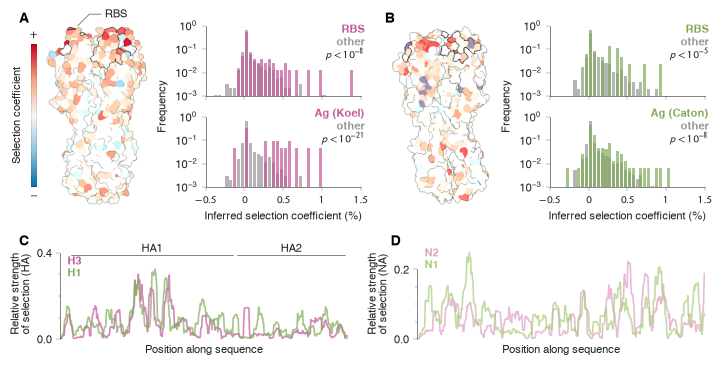

,value
figure_key,paper.selection_structure_space
intended_output_name,paper/fig-selection-structure-space.pdf
profile,paper_v1
canvas_name,double_half
canvas_size_inches,"(7.244094488188976, 3.622047244094488)"
minimum_mutation_count,20
structure_assets,(/Users/jpb156/Library/CloudStorage/Dropbox/gi...
saved_path,/Users/jpb156/Library/CloudStorage/Dropbox/git...


Functional Sites


,label,subtype,subset_id,subset_label,subset_count,other_count,subset_mean_selection,other_mean_selection,t_statistic,p_value,p_value_label
0,H3,h3n2,rbs,RBS,78,950,0.001339,0.000412,6.058183,1.930230e-09,$p < 10^{-8}$
1,H3,h3n2,koel,Ag (Koel),21,1007,0.003184,0.000426,9.903053,3.829033e-22,$p < 10^{-21}$
2,H1,h1n1,rbs,RBS,45,1025,0.001568,0.000559,4.766197,2.136841e-06,$p < 10^{-5}$
3,H1,h1n1,canton_globular_head,Ag (Caton),149,921,0.001222,0.000501,5.905128,4.730252e-09,$p < 10^{-8}$


Selection Curves


,label,subtype,segment,point_count,minimum_position,maximum_position,minimum_selection,maximum_selection
0,H3,h3n2,ha,566,1,566,0.0,0.301310
1,H1,h1n1,ha,566,1,566,0.0,0.324697
2,N2,h3n2,na,469,1,469,0.0,0.221930
3,N1,h1n1,na,469,1,469,0.0,0.247848


/Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/paper/fig-selection-structure-space.pdf

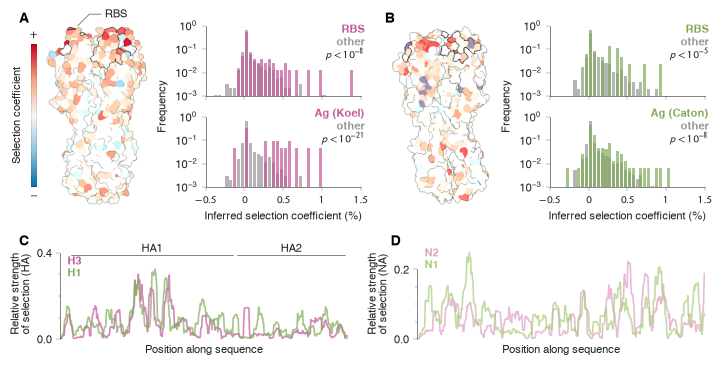

In [2]:
# Main Figure 2: Selection, structure, and convergent landscapes
INPUT_DIRECTORY = ROOT / "data" / "plotting"
INPUTS = [
    INPUT_DIRECTORY / "inputs" / "selection",
    INPUT_DIRECTORY / "derived" / "structure" / "sasa_selection.csv",
    INPUT_DIRECTORY / "inputs" / "structure",
]
MINIMUM_MUTATION_COUNT = 20
# FIXED_DISPLAY_METADATA: outer ticks retain the manuscript labels while the
# limits provide room for every curve and the HA-domain annotations.
SELECTION_Y_LIMITS = {"HA": (0, 0.42), "NA": (0, 0.26)}
SELECTION_TOP_TICKS = {"HA": 0.4, "NA": 0.2}
VERSION = "paper"
OUTPUT_FILE = ROOT / "figures" / "paper" / "fig-selection-structure-space.pdf"

assert all(path.exists() for path in INPUTS)
if SAVE:
    result = f.plot_selection_structure_space(
        input_directory=INPUT_DIRECTORY,
        minimum_mutation_count=MINIMUM_MUTATION_COUNT,
        version=VERSION,
        output_file=OUTPUT_FILE,
        overwrite=OVERWRITE,
    )
    display(result.figure)
    AUDIT = display_figure_audit(result)
    link_to(OUTPUT_FILE)


## Main Figure 3 - Fixation probability and AUROC improvement

**Status: RUNNABLE**

- Canonical output: `figures/paper/fig-pfix-dauc.pdf`
- Entry point: `figures.plot_pfix_dauc`
- Data/adapter note: Canonical inputs: `data/plotting/derived/fixation_metrics/fixation_probability.csv` and `data/plotting/derived/fixation_metrics/auc.csv`; the wrapper selects the full-model, all-time, 1,095-day records explicitly.
- Statistical readout: `result.audit`, with the exact frequency bins and AUROC summaries.


Fixation:      /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/data/plotting/derived/fixation_metrics/fixation_probability.csv
AUROC:         /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/data/plotting/derived/fixation_metrics/auc.csv
Model:         full_model
Source:        all_time
Warmup:        >= 1095 days
Appearance:    paper_v1; double_over_2_8; 7.244 x 2.587 inches
Plot code:     /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/src/influenza_figures/fixation_plot.py
Output:        /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/paper/fig-pfix-dauc.pdf


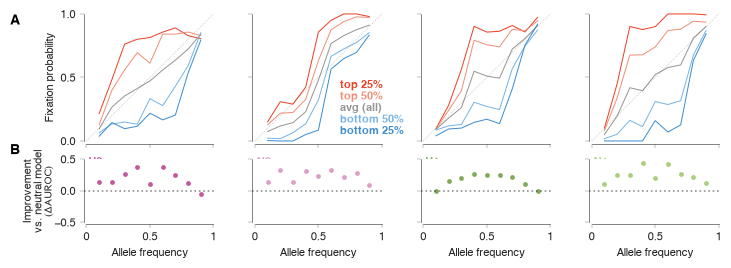

,value
figure_key,paper.pfix_dauc
intended_output_name,paper/fig-pfix-dauc.pdf
profile,paper_v1
canvas_name,double_over_2_8
canvas_size_inches,"(7.244094488188976, 2.5871766029246346)"
layout,four_columns_by_two_rows
model_id,full_model
source_variant,all_time
minimum_observation_day,1095
input_paths,(/Users/jpb156/Library/CloudStorage/Dropbox/gi...


Panels


,label,subtype,segment,fixation_probability_row_count,auc_row_count,frequency_bins,mean_model_auc,mean_null_auc,mean_delta_auc,minimum_delta_auc,maximum_delta_auc
0,H3,h3n2,ha,9,9,"(0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)",0.735975,0.544912,0.191063,-0.050780,0.383214
1,N2,h3n2,na,9,9,"(0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)",0.761911,0.533258,0.228653,0.089889,0.330888
2,H1,h1n1,ha,9,9,"(0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)",0.717771,0.559537,0.158235,-0.010369,0.266742
3,N1,h1n1,na,9,9,"(0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)",0.821480,0.566789,0.254691,0.102474,0.438058


/Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/paper/fig-pfix-dauc.pdf

In [4]:
# Main Figure 3: Fixation probability and AUROC improvement
FIXATION_PROBABILITY_FILE = ROOT / "data" / "plotting" / "derived" / "fixation_metrics" / "fixation_probability.csv"
AUC_FILE = ROOT / "data" / "plotting" / "derived" / "fixation_metrics" / "auc.csv"
# FIXED_RECIPE_METADATA: model and source are enforced by f.plot_pfix_dauc.
MODEL_ID = "full_model"
AUC_SOURCE_VARIANT = "all_time"
MINIMUM_OBSERVATION_DAY = 1095
VERSION = "paper"
OUTPUT_FILE = ROOT / "figures" / "paper" / "fig-pfix-dauc.pdf"

assert FIXATION_PROBABILITY_FILE.is_file() and AUC_FILE.is_file()
if SAVE:
    result = f.plot_pfix_dauc(
        fixation_probability_file=FIXATION_PROBABILITY_FILE,
        auc_file=AUC_FILE,
        minimum_observation_day=MINIMUM_OBSERVATION_DAY,
        version=VERSION,
        output_file=OUTPUT_FILE,
        overwrite=OVERWRITE,
    )
    display(result.figure)
    AUDIT = display_figure_audit(result)
    link_to(OUTPUT_FILE)


## Main Figure 4 - Full model versus neutral forecasts, 9 months

**Status: RUNNABLE**

- Canonical output: `figures/paper/fig-emd-vs-null-9m.pdf`
- Entry point: `figures.plot_emd_comparison`
- Data/adapter note: Scientific recipe: `best GenModel` versus neutral, exact `evaluation_id` pairing, `results_grid`, and the inclusive 1,095-day warmup.
- Statistical readout: `result.audit`; the run cell displays paired n, mean delta EMD, t statistic, and p-value for every protein.


Input:      /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/data/plotting/inputs/emd
Comparison: full model vs neutral model
Horizon:    9 months (results_grid)
Full model: cross-validation-selected best GenModel [full_model_cross_validated_rare_filtered]
Appearance: paper_v1; double_over_2_2; 7.244 x 3.293 inches
Plot code:  /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/src/influenza_figures/emd_plot.py
Output:     /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/paper/fig-emd-vs-null-9m.pdf
H3N2: on or after 2012-01-02 (initial inference 2009-01-02 + 1095 days; evaluation model_start_date)
H1N1: on or after 2012-05-01 (initial inference 2009-05-02 + 1095 days; evaluation model_start_date)


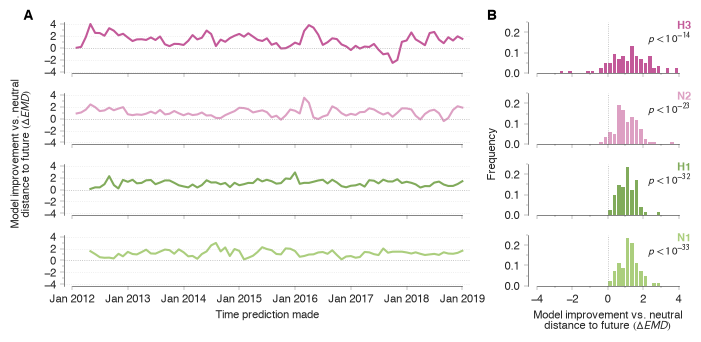

,protein,subtype,segment,paired_n,first_observation,last_observation,mean_delta_emd,median_delta_emd,t_statistic,p_value,significant_at_0.05,full_model_worse
0,H3,h3n2,ha,84,2012-02-01,2019-01-01,1.218366,1.308650,9.594964,4.219818e-15,True,False
1,N2,h3n2,na,84,2012-02-01,2019-01-01,1.048452,0.979468,14.476189,2.020053e-24,True,False
2,H1,h1n1,ha,81,2012-05-01,2019-01-01,1.090358,1.105476,19.963386,8.216591e-33,True,False
3,N1,h1n1,na,81,2012-05-01,2019-01-01,1.221930,1.155670,20.629342,9.074223e-34,True,False


/Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/paper/fig-emd-vs-null-9m.pdf

In [5]:
# Main Figure 4: Full model versus neutral forecasts, 9 months
INPUT_DIRECTORY = ROOT / "data" / "plotting" / "inputs" / "emd"
INPUTS = [INPUT_DIRECTORY / name for name in ("evaluations.csv", "values.csv", "methods.csv", "sources.csv")]
COMPARATOR = "null"
HORIZON_MONTHS = 9
# FIXED_RECIPE_METADATA: enforced inside f.plot_emd_comparison; shown here
# so the reviewed scientific choices remain visible, not as editable arguments.
EVALUATION_PROTOCOL = "results_grid"
FULL_MODEL_SOURCE = f.FULL_MODEL_SOURCE_BY_HORIZON[HORIZON_MONTHS]
WARMUP_DAYS = 1095
VERSION = "paper"
OUTPUT_FILE = ROOT / "figures" / "paper" / "fig-emd-vs-null-9m.pdf"

assert all(path.is_file() for path in INPUTS)
if SAVE:
    result = f.plot_emd_comparison(
        comparator=COMPARATOR,
        horizon_months=HORIZON_MONTHS,
        input_directory=INPUT_DIRECTORY,
        version=VERSION,
        output_file=OUTPUT_FILE,
        overwrite=OVERWRITE,
    )
    display(result.figure)
    STATISTICS = display_emd_statistics(result)
    link_to(OUTPUT_FILE)


## Main Figure 5 - Mutation effects, backgrounds, and clade forecasts

**Status: RUNNABLE**

- Canonical output: `figures/paper/fig-dw-clade.pdf`
- Entry point: `figures.plot_background_clade`
- Data/adapter note: Canonical inputs: `data/plotting/inputs/background/population_fitness.csv` and `data/plotting/inputs/clades/h3n2_ha_frequencies.csv`. The renderer first applies the inclusive 90-day duration cutoff, then selects the earliest eligible source record for each mutation identity. Panel B uses a -1.6% to +1.6% vertical range, and the background-panel y-axis lines terminate at their outer major ticks.
- Statistical readout: `result.audit`, with fixed-versus-lost n, means, test statistics, and p-values for all three background quantities.


Background:    /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/data/plotting/inputs/background/population_fitness.csv
Clades:        /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/data/plotting/inputs/clades/h3n2_ha_frequencies.csv
Mutations:     duration >= 90 days; earliest eligible record per identity
Panel B range: -1.6% to 1.6%
Y-axis lines:  spines end at outer major ticks
Clade filter:  total observed frequency > 1.0
Dates:         2011-08-01 to 2015-06-01
Appearance:    paper_v1; one_five_over_1_4; 4.764 x 3.403 inches
Plot code:     /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/src/influenza_figures/background_plot.py
Output:        /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/paper/fig-dw-clade.pdf


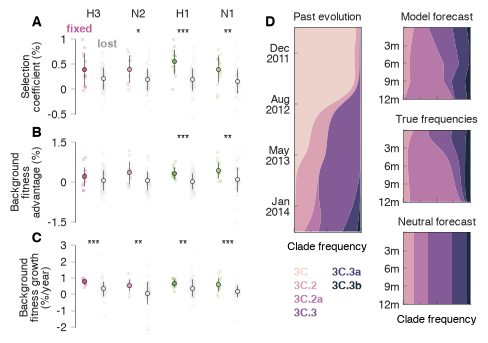

,value
figure_key,paper.dw_clade
intended_output_name,paper/fig-dw-clade.pdf
profile,paper_v1
canvas_name,one_five_over_1_4
canvas_size_inches,"(4.763779527559055, 3.402699662542182)"
layout,three_by_four_background_summaries_with_clade_...
background_source,/Users/jpb156/Library/CloudStorage/Dropbox/git...
data_release,background_fitness_v2
event_count_before_filter,418
retained_event_count,315


Panels


,metric,metric_label,units,label,subtype,segment,minimum_duration_days,fixed_count,lost_count,fixed_mean,lost_mean,welch_t_statistic,welch_p_value
0,selection_coefficient,Inferred selection coefficient (%),percentage points,H3,h3n2,ha,90,13,71,0.397287,0.218687,1.858497,8.429382e-02
1,selection_coefficient,Inferred selection coefficient (%),percentage points,N2,h3n2,na,90,11,68,0.408064,0.199198,2.306646,3.974881e-02
2,selection_coefficient,Inferred selection coefficient (%),percentage points,H1,h1n1,ha,90,13,75,0.555448,0.202020,4.488950,4.414242e-04
3,selection_coefficient,Inferred selection coefficient (%),percentage points,N1,h1n1,na,90,17,47,0.411670,0.168174,3.239389,3.283131e-03
4,initial_background_minus_population_fitness,Difference between initial background fitness ...,percentage points,H3,h3n2,ha,90,13,71,0.215552,0.084243,1.141131,2.696550e-01
5,initial_background_minus_population_fitness,Difference between initial background fitness ...,percentage points,N2,h3n2,na,90,11,68,0.371158,0.066755,2.165543,5.077384e-02
6,initial_background_minus_population_fitness,Difference between initial background fitness ...,percentage points,H1,h1n1,ha,90,13,75,0.357545,0.044571,4.407611,2.424392e-04
7,initial_background_minus_population_fitness,Difference between initial background fitness ...,percentage points,N1,h1n1,na,90,17,47,0.464535,0.117718,3.395767,1.465538e-03
8,annualized_background_fitness_change,Change in background fitness per year (%),% per year,H3,h3n2,ha,90,13,71,0.787274,0.351934,6.237451,6.038164e-08
9,annualized_background_fitness_change,Change in background fitness per year (%),% per year,N2,h3n2,na,90,11,68,0.544870,0.104464,3.147258,4.587564e-03


/Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/paper/fig-dw-clade.pdf

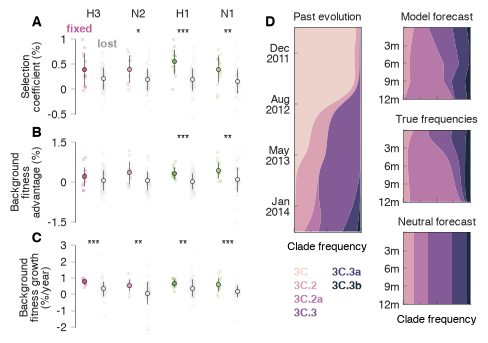

In [2]:
# Main Figure 5: Mutation effects, backgrounds, and clade forecasts
BACKGROUND_FILE = ROOT / "data" / "plotting" / "inputs" / "background" / "population_fitness.csv"
CLADE_FILE = ROOT / "data" / "plotting" / "inputs" / "clades" / "h3n2_ha_frequencies.csv"
# FIXED_RECIPE_METADATA: outcomes and initial/final times were assigned
# upstream; the plot does not reconstruct them from sparse observations. It
# first applies the inclusive duration cutoff, then selects the earliest
# eligible start_time record for each mutation identity. Clade filters and
# dates remain editable below.
EMERGENCE_THRESHOLD = 0.05
FIXATION_THRESHOLD = 0.95
MUTATION_IDENTITY_FIELDS = ("subtype", "segment", "position", "state")
REPRESENTATIVE_RECORD = "earliest eligible start_time"
MINIMUM_DURATION_DAYS = 90
# FIXED_DISPLAY_METADATA: these document renderer settings in background_plot.py.
BACKGROUND_ADVANTAGE_Y_LIMITS_PERCENT = (-1.6, 1.6)
BACKGROUND_Y_SPINE_BOUNDS = "outer major ticks"
MINIMUM_TOTAL_CLADE_FREQUENCY = 1.0
START_DATE = "2011-08-01"
END_DATE = "2015-06-01"
FORECAST_BASELINE_DATE = "2014-06-01"
VERSION = "paper"
OUTPUT_FILE = ROOT / "figures" / "paper" / "fig-dw-clade.pdf"

assert BACKGROUND_FILE.is_file() and CLADE_FILE.is_file()
if SAVE:
    result = f.plot_background_clade(
        background_file=BACKGROUND_FILE,
        clade_file=CLADE_FILE,
        minimum_total_frequency=MINIMUM_TOTAL_CLADE_FREQUENCY,
        start_date=START_DATE,
        end_date=END_DATE,
        forecast_baseline_date=FORECAST_BASELINE_DATE,
        version=VERSION,
        output_file=OUTPUT_FILE,
        overwrite=OVERWRITE,
    )
    display(result.figure)
    AUDIT = display_figure_audit(result)
    link_to(OUTPUT_FILE)


# Supplementary figures


## Supplementary Figure S1 - Toy-model selection inference

**Status: MISSING SOURCE**

- Canonical output: `not registered; intended figures/supplement/fig-toy-selection-inference.pdf`
- Entry point: none in the active repository
- Data/adapter note: The archived PDF `selection_coeff_inference_toy_model_shared_cbar.pdf` is a reference only. An active canonical table containing the 1,000 replicate true and inferred coefficients is missing.
- Statistical readout: a future recipe should expose replicate count and true/inferred error summaries.


## Supplementary Figure S2 - Toy-model fixation probability and AUROC

**Status: OUT OF SCOPE**

- Canonical output: `figures/supplement/fig-toy-fixation-auc.pdf`
- Entry point: a canonical adapter based on `notebooks/Fig_AUC_and_Fix_Prob_layout_toy_model_Py.ipynb`
- Data/adapter note: Related inputs and plotting code exist, but the historical panel order does not match the draft. S2 was not included in the supplied final-figure set, so it is deliberately outside this migration pass.
- Statistical readout: fixation-probability and AUROC values by frequency bin for both learned-model and neutral predictions.


## Supplementary Figure S3 - Toy-model EMD versus forecast horizon

**Status: OUT OF SCOPE**

- Canonical output: `figures/supplement/fig-toy-emd-vs-horizon.pdf`
- Entry point: a canonical adapter based on `notebooks/Fig_EMD_toy_model_Py.ipynb`
- Data/adapter note: The plotting notebook and archived result family have not been migrated into one active, documented table and wrapper. S3 was not included in the supplied final-figure set.
- Statistical readout: sample count and mean/uncertainty for learned, neutral, and lower-bound EMD at every horizon.


## Supplementary Figure S4 - Sequence counts through time

**Status: OUT OF SCOPE**

- Canonical output: `figures/supplement/fig-sequence-counts.pdf`
- Entry point: a canonical wrapper based on `notebooks/Fig_numb_seq_per_month_Py.ipynb`
- Data/adapter note: Canonical input: `data/plotting/inputs/surveillance/sequences_by_year.csv`. The active table is ready, but S4 was not included in the supplied final-figure set and remains outside this migration pass.
- Statistical readout: the plotted date range and per-protein sequence totals should be returned with the figure.


## Supplementary Figure S5 - Allele frequencies and selection distributions

**Status: RUNNABLE**

- Canonical output: `figures/supplement/fig-frequency-selection.pdf`
- Entry point: `figures.plot_frequency_selection`
- Data/adapter note: Canonical inputs: `data/plotting/inputs/frequencies/` and `data/plotting/inputs/selection/*_mutations.csv`. The wrapper keeps the four protein-specific time shifts visible.
- Statistical readout: `result.audit`, including plotted trajectory and mutation counts.


Input:         /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/data/plotting
Filter:        mutation_count >= 20
Appearance:    paper_v1; double_over_1_8; 7.244 x 4.024 inches
Plot code:     /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/src/influenza_figures/selection_plot.py
Output:        /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/supplement/fig-frequency-selection.pdf


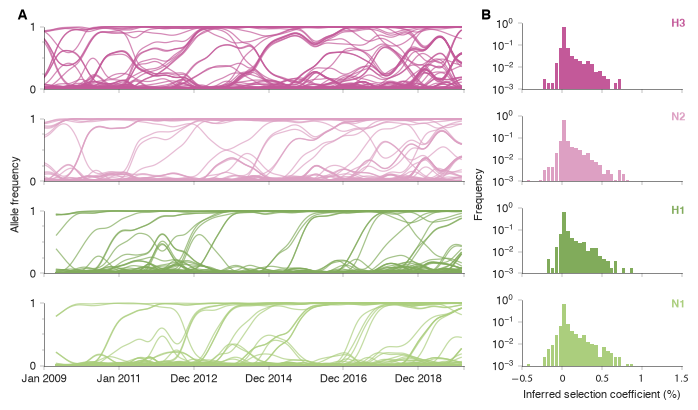

,value
figure_key,paper.frequency_selection
intended_output_name,supplement/fig-frequency-selection.pdf
profile,paper_v1
canvas_name,double_over_1_8
canvas_size_inches,"(7.244094488188976, 4.024496937882764)"
minimum_mutation_count,20
allele_frequency_display_threshold,0.01
initial_wild_type_filter_threshold,0.95
saved_path,/Users/jpb156/Library/CloudStorage/Dropbox/git...


Panels


,label,subtype,segment,time_shift_days,time_point_count,total_trajectory_count,plotted_trajectory_count,total_mutation_count,plotted_mutation_count,minimum_selection_coefficient,maximum_selection_coefficient
0,H3,h3n2,ha,0,408,11886,322,2464,1028,-0.003888,0.013579
1,N2,h3n2,na,0,408,9849,270,2214,884,-0.004238,0.008285
2,H1,h1n1,ha,120,396,11886,313,2725,1070,-0.005779,0.010010
3,N1,h1n1,na,120,396,9849,252,2020,844,-0.004301,0.008937


/Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/supplement/fig-frequency-selection.pdf

In [7]:
# Supplementary Figure S5: Allele frequencies and selection distributions
INPUT_DIRECTORY = ROOT / "data" / "plotting"
FREQUENCY_DIRECTORY = INPUT_DIRECTORY / "inputs" / "frequencies"
SELECTION_DIRECTORY = INPUT_DIRECTORY / "inputs" / "selection"
MINIMUM_MUTATION_COUNT = 20
# FIXED_RECIPE_METADATA: these display alignments are enforced by the reviewed
# frequency renderer; the mutation-count filter below is an editable argument.
H1_TIME_SHIFT_DAYS = 120
H3_TIME_SHIFT_DAYS = 0
VERSION = "paper"
OUTPUT_FILE = ROOT / "figures" / "supplement" / "fig-frequency-selection.pdf"

assert FREQUENCY_DIRECTORY.is_dir() and SELECTION_DIRECTORY.is_dir()
if SAVE:
    result = f.plot_frequency_selection(
        input_directory=INPUT_DIRECTORY,
        minimum_mutation_count=MINIMUM_MUTATION_COUNT,
        version=VERSION,
        output_file=OUTPUT_FILE,
        overwrite=OVERWRITE,
    )
    display(result.figure)
    AUDIT = display_figure_audit(result)
    link_to(OUTPUT_FILE)


## Supplementary Figure S6 - Selection versus solvent accessibility

**Status: RUNNABLE**

- Canonical output: `figures/supplement/fig-selection-sasa.pdf`
- Entry point: `figures.plot_selection_sasa`
- Data/adapter note: Canonical input: `data/plotting/derived/structure/sasa_selection.csv`, read as one maintained long table. Selection-axis limits are HA 0-0.42 (top tick 0.4) and NA 0-0.26 (top tick 0.2); SASA limits are 0-100 (top tick 80).
- Statistical readout: `result.audit`, including Pearson and Spearman correlations, p-values, and paired n.


Input:         /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/data/plotting
Data:          smoothed selection and solvent accessibility
Selection y:   HA 0-0.42 (top tick 0.4); NA 0-0.26 (top tick 0.2)
SASA y:        0-100 (top tick 80)
Appearance:    paper_v1; double_half; 7.244 x 3.622 inches
Plot code:     /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/src/influenza_figures/selection_plot.py
Output:        /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/supplement/fig-selection-sasa.pdf


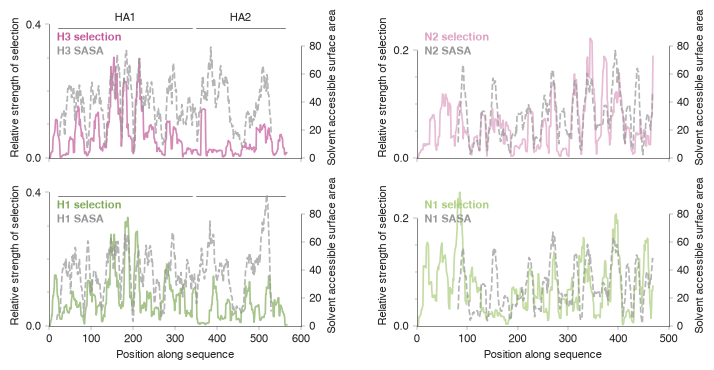

,value
figure_key,paper.selection_sasa
intended_output_name,supplement/fig-selection-sasa.pdf
profile,paper_v1
canvas_name,double_half
canvas_size_inches,"(7.244094488188976, 3.622047244094488)"
saved_path,/Users/jpb156/Library/CloudStorage/Dropbox/git...


Panels


,label,subtype,segment,point_count,positive_sasa_count,maximum_selection,maximum_sasa
0,H3,h3n2,ha,566,505,0.301310,79.045295
1,H1,h1n1,ha,566,512,0.324697,93.689687
2,N2,h3n2,na,469,388,0.221930,76.618474
3,N1,h1n1,na,469,388,0.247848,66.748054


Correlations


,label,subtype,segment,domain,paired_count,pearson_r,pearson_p_value,spearman_r,spearman_p_value
0,H3,h3n2,ha,full,505,0.507577,2.010913e-34,0.507701,1.926239e-34
1,H3,h3n2,ha,HA1,321,0.637637,4.947503e-38,0.682529,2.381377e-45
2,H3,h3n2,ha,HA2,184,0.281588,1.078304e-04,0.230202,1.668506e-03
3,N2,h3n2,na,full,388,0.589992,9.411161e-38,0.600701,2.042615e-39
4,H1,h1n1,ha,full,512,0.308736,9.060421e-13,0.309556,7.833097e-13
5,H1,h1n1,ha,HA1,328,0.458971,1.709825e-18,0.464305,6.095226e-19
6,H1,h1n1,ha,HA2,184,0.274237,1.651822e-04,0.232076,1.524531e-03
7,N1,h1n1,na,full,388,0.367375,7.654869e-14,0.321902,8.363034e-11


/Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/supplement/fig-selection-sasa.pdf

In [3]:
# Supplementary Figure S6: Selection versus solvent accessibility
INPUT_DIRECTORY = ROOT / "data" / "plotting"
INPUT_FILE = INPUT_DIRECTORY / "derived" / "structure" / "sasa_selection.csv"
# FIXED_DISPLAY_METADATA: limits extend beyond the outer ticks so curves are
# not clipped while the manuscript tick labels remain unchanged.
SELECTION_Y_LIMITS = {"HA": (0, 0.42), "NA": (0, 0.26)}
SELECTION_TOP_TICKS = {"HA": 0.4, "NA": 0.2}
SASA_Y_LIMITS = (0, 100)
SASA_TOP_TICK = 80
VERSION = "paper"
OUTPUT_FILE = ROOT / "figures" / "supplement" / "fig-selection-sasa.pdf"

assert INPUT_FILE.is_file()
if SAVE:
    result = f.plot_selection_sasa(
        input_directory=INPUT_DIRECTORY,
        version=VERSION,
        output_file=OUTPUT_FILE,
        overwrite=OVERWRITE,
    )
    display(result.figure)
    AUDIT = display_figure_audit(result)
    link_to(OUTPUT_FILE)


## Supplementary Figure S7 - Full-model fixation AUROC

**Status: RUNNABLE**

- Canonical output: `figures/supplement/fig-fixation-auc.pdf`
- Entry point: `figures.plot_fixation_auc`
- Data/adapter note: Canonical input: `data/plotting/derived/fixation_metrics/auc.csv`, filtered to the full model, all-time source, and 1,095-day minimum observation time.
- Statistical readout: `result.audit`, with exact frequency bins and AUROC summaries.


Input:         /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/data/plotting/derived/fixation_metrics/auc.csv
Model:         full_model
Source:        all_time
Warmup:        >= 1095 days
Appearance:    paper_v1; single_tall_1_5; 3.465 x 5.197 inches
Plot code:     /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/src/influenza_figures/fixation_plot.py
Output:        /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/supplement/fig-fixation-auc.pdf


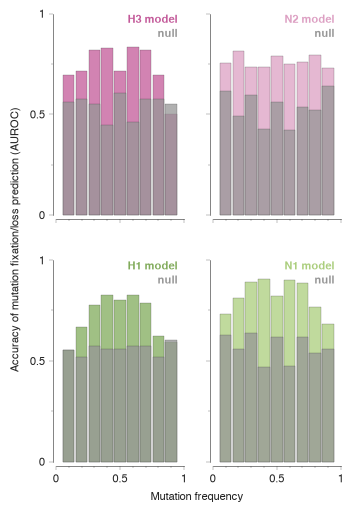

,value
figure_key,paper.auc
intended_output_name,supplement/fig-fixation-auc.pdf
profile,paper_v1
canvas_name,single_tall_1_5
canvas_size_inches,"(3.4645669291338583, 5.196850393700787)"
layout,two_by_two
model_id,full_model
source_variant,all_time
minimum_observation_day,1095
input_paths,(/Users/jpb156/Library/CloudStorage/Dropbox/gi...


Panels


,label,subtype,segment,fixation_probability_row_count,auc_row_count,frequency_bins,mean_model_auc,mean_null_auc,mean_delta_auc,minimum_delta_auc,maximum_delta_auc
0,H3,h3n2,ha,0,9,"(0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)",0.735975,0.544912,0.191063,-0.050780,0.383214
1,N2,h3n2,na,0,9,"(0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)",0.761911,0.533258,0.228653,0.089889,0.330888
2,H1,h1n1,ha,0,9,"(0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)",0.717771,0.559537,0.158235,-0.010369,0.266742
3,N1,h1n1,na,0,9,"(0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)",0.821480,0.566789,0.254691,0.102474,0.438058


/Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/supplement/fig-fixation-auc.pdf

In [9]:
# Supplementary Figure S7: Full-model fixation AUROC
AUC_FILE = ROOT / "data" / "plotting" / "derived" / "fixation_metrics" / "auc.csv"
# FIXED_RECIPE_METADATA: model and source are enforced by f.plot_fixation_auc.
MODEL_ID = "full_model"
SOURCE_VARIANT = "all_time"
MINIMUM_OBSERVATION_DAY = 1095
VERSION = "paper"
OUTPUT_FILE = ROOT / "figures" / "supplement" / "fig-fixation-auc.pdf"

assert AUC_FILE.is_file()
if SAVE:
    result = f.plot_fixation_auc(
        auc_file=AUC_FILE,
        minimum_observation_day=MINIMUM_OBSERVATION_DAY,
        version=VERSION,
        output_file=OUTPUT_FILE,
        overwrite=OVERWRITE,
    )
    display(result.figure)
    AUDIT = display_figure_audit(result)
    link_to(OUTPUT_FILE)


## Supplementary Figure S8 - Full model versus neutral forecasts, 6 months

**Status: RUNNABLE**

- Canonical output: `figures/supplement/fig-emd-vs-null-6m.pdf`
- Entry point: `figures.plot_emd_comparison`
- Data/adapter note: One explicit six-month neutral-comparison recipe.
- Statistical readout: `result.audit`, displayed as a paired EMD t-test table.


Input:      /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/data/plotting/inputs/emd
Comparison: full model vs neutral model
Horizon:    6 months (results_grid)
Full model: cross-validation-selected best GenModel [full_model_cross_validated_rare_filtered]
Appearance: paper_v1; double_over_2_2; 7.244 x 3.293 inches
Plot code:  /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/src/influenza_figures/emd_plot.py
Output:     /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/supplement/fig-emd-vs-null-6m.pdf
H3N2: on or after 2012-01-02 (initial inference 2009-01-02 + 1095 days; evaluation model_start_date)
H1N1: on or after 2012-05-01 (initial inference 2009-05-02 + 1095 days; evaluation model_start_date)


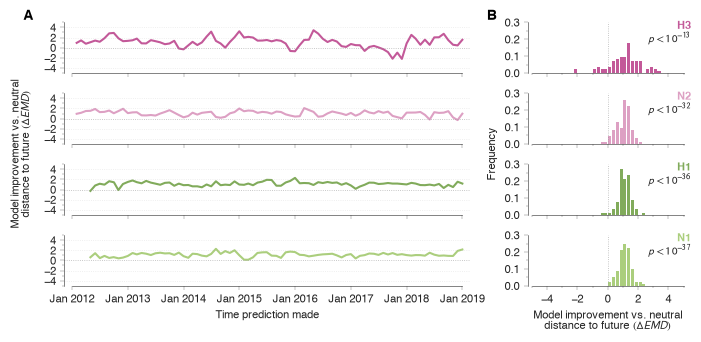

,protein,subtype,segment,paired_n,first_observation,last_observation,mean_delta_emd,median_delta_emd,t_statistic,p_value,significant_at_0.05,full_model_worse
0,H3,h3n2,ha,84,2012-02-01,2019-01-01,1.079772,1.188123,9.294837,1.678777e-14,True,False
1,N2,h3n2,na,84,2012-02-01,2019-01-01,1.039103,1.145821,19.572954,7.628046e-33,True,False
2,H1,h1n1,ha,81,2012-05-01,2019-01-01,1.100857,1.148717,23.229159,2.615724e-37,True,False
3,N1,h1n1,na,81,2012-05-01,2019-01-01,1.133143,1.093379,24.104478,1.955173e-38,True,False


/Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/supplement/fig-emd-vs-null-6m.pdf

In [10]:
# Supplementary Figure S8: Full model versus neutral forecasts, 6 months
INPUT_DIRECTORY = ROOT / "data" / "plotting" / "inputs" / "emd"
INPUTS = [INPUT_DIRECTORY / name for name in ("evaluations.csv", "values.csv", "methods.csv", "sources.csv")]
COMPARATOR = "null"
HORIZON_MONTHS = 6
# FIXED_RECIPE_METADATA: enforced inside f.plot_emd_comparison; shown here
# so the reviewed scientific choices remain visible, not as editable arguments.
EVALUATION_PROTOCOL = "results_grid"
FULL_MODEL_SOURCE = f.FULL_MODEL_SOURCE_BY_HORIZON[HORIZON_MONTHS]
WARMUP_DAYS = 1095
VERSION = "paper"
OUTPUT_FILE = ROOT / "figures" / "supplement" / "fig-emd-vs-null-6m.pdf"

assert all(path.is_file() for path in INPUTS)
if SAVE:
    result = f.plot_emd_comparison(
        comparator=COMPARATOR,
        horizon_months=HORIZON_MONTHS,
        input_directory=INPUT_DIRECTORY,
        version=VERSION,
        output_file=OUTPUT_FILE,
        overwrite=OVERWRITE,
    )
    display(result.figure)
    STATISTICS = display_emd_statistics(result)
    link_to(OUTPUT_FILE)


## Supplementary Figure S9 - Full model versus neutral forecasts, 12 months

**Status: RUNNABLE**

- Canonical output: `figures/supplement/fig-emd-vs-null-12m.pdf`
- Entry point: `figures.plot_emd_comparison`
- Data/adapter note: One explicit twelve-month neutral-comparison recipe.
- Statistical readout: `result.audit`, displayed as a paired EMD t-test table.


Input:      /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/data/plotting/inputs/emd
Comparison: full model vs neutral model
Horizon:    12 months (results_grid)
Full model: cross-validation-selected best GenModel [full_model_cross_validated_rare_filtered]
Appearance: paper_v1; double_over_2_2; 7.244 x 3.293 inches
Plot code:  /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/src/influenza_figures/emd_plot.py
Output:     /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/supplement/fig-emd-vs-null-12m.pdf
H3N2: on or after 2012-01-02 (initial inference 2009-01-02 + 1095 days; evaluation model_start_date)
H1N1: on or after 2012-05-01 (initial inference 2009-05-02 + 1095 days; evaluation model_start_date)


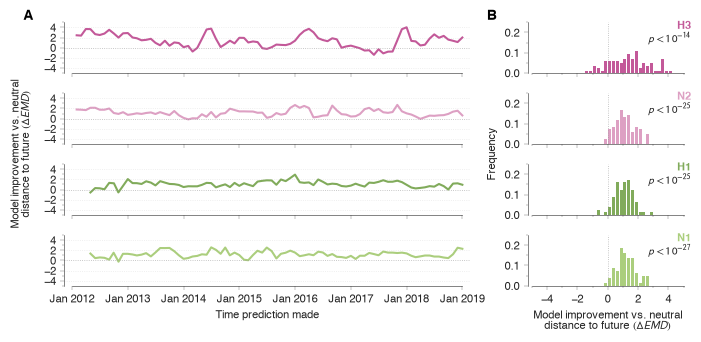

,protein,subtype,segment,paired_n,first_observation,last_observation,mean_delta_emd,median_delta_emd,t_statistic,p_value,significant_at_0.05,full_model_worse
0,H3,h3n2,ha,84,2012-02-01,2019-01-01,1.375293,1.370038,9.814161,1.542146e-15,True,False
1,N2,h3n2,na,84,2012-02-01,2019-01-01,1.136611,1.084903,15.605743,2.072408e-26,True,False
2,H1,h1n1,ha,81,2012-05-01,2019-01-01,1.054642,1.090535,16.006505,1.163251e-26,True,False
3,N1,h1n1,na,81,2012-05-01,2019-01-01,1.201552,1.143015,17.139870,1.656103e-28,True,False


/Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/supplement/fig-emd-vs-null-12m.pdf

In [11]:
# Supplementary Figure S9: Full model versus neutral forecasts, 12 months
INPUT_DIRECTORY = ROOT / "data" / "plotting" / "inputs" / "emd"
INPUTS = [INPUT_DIRECTORY / name for name in ("evaluations.csv", "values.csv", "methods.csv", "sources.csv")]
COMPARATOR = "null"
HORIZON_MONTHS = 12
# FIXED_RECIPE_METADATA: enforced inside f.plot_emd_comparison; shown here
# so the reviewed scientific choices remain visible, not as editable arguments.
EVALUATION_PROTOCOL = "results_grid"
FULL_MODEL_SOURCE = f.FULL_MODEL_SOURCE_BY_HORIZON[HORIZON_MONTHS]
WARMUP_DAYS = 1095
VERSION = "paper"
OUTPUT_FILE = ROOT / "figures" / "supplement" / "fig-emd-vs-null-12m.pdf"

assert all(path.is_file() for path in INPUTS)
if SAVE:
    result = f.plot_emd_comparison(
        comparator=COMPARATOR,
        horizon_months=HORIZON_MONTHS,
        input_directory=INPUT_DIRECTORY,
        version=VERSION,
        output_file=OUTPUT_FILE,
        overwrite=OVERWRITE,
    )
    display(result.figure)
    STATISTICS = display_emd_statistics(result)
    link_to(OUTPUT_FILE)


## Supplementary Figure S10 - Full model versus MLR forecasts, 6 months

**Status: RUNNABLE**

- Canonical output: `figures/supplement/fig-emd-vs-mlr-6m.pdf`
- Entry point: `figures.plot_emd_comparison`
- Data/adapter note: One explicit six-month comparison. MLR means multinomial logistic regression.
- Statistical readout: `result.audit`, displayed as a paired EMD t-test table.


Input:      /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/data/plotting/inputs/emd
Comparison: full model vs multinomial logistic regression (MLR)
Horizon:    6 months (results_grid)
Full model: cross-validation-selected best GenModel [full_model_cross_validated_rare_filtered]
Appearance: paper_v1; double_over_1_9; 7.244 x 3.813 inches
Plot code:  /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/src/influenza_figures/emd_plot.py
Output:     /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/supplement/fig-emd-vs-mlr-6m.pdf
H3N2: on or after 2012-01-02 (initial inference 2009-01-02 + 1095 days; evaluation model_start_date)
H1N1: on or after 2012-05-01 (initial inference 2009-05-02 + 1095 days; evaluation model_start_date)


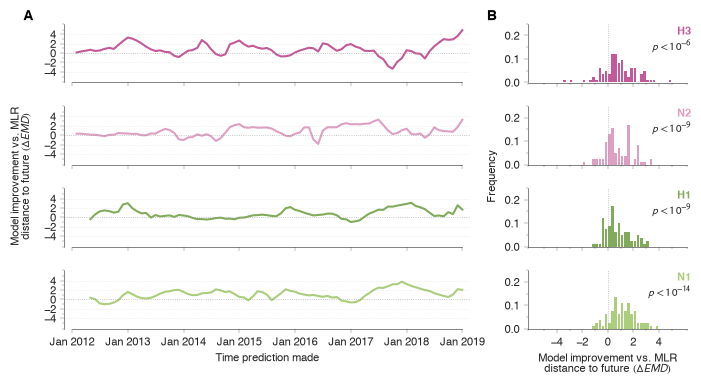

,protein,subtype,segment,paired_n,first_observation,last_observation,mean_delta_emd,median_delta_emd,t_statistic,p_value,significant_at_0.05,full_model_worse
0,H3,h3n2,ha,84,2012-02-01,2019-01-01,0.843323,0.748619,5.676807,1.962605e-07,True,False
1,N2,h3n2,na,84,2012-02-01,2019-01-01,0.821486,0.507401,7.048447,4.914439e-10,True,False
2,H1,h1n1,ha,81,2012-05-01,2019-01-01,0.791567,0.568835,7.215652,2.725004e-10,True,False
3,N1,h1n1,na,81,2012-05-01,2019-01-01,1.140096,1.095734,9.877568,1.674939e-15,True,False


/Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/supplement/fig-emd-vs-mlr-6m.pdf

In [12]:
# Supplementary Figure S10: Full model versus MLR forecasts, 6 months
INPUT_DIRECTORY = ROOT / "data" / "plotting" / "inputs" / "emd"
INPUTS = [INPUT_DIRECTORY / name for name in ("evaluations.csv", "values.csv", "methods.csv", "sources.csv")]
COMPARATOR = "MLR"
HORIZON_MONTHS = 6
# FIXED_RECIPE_METADATA: enforced inside f.plot_emd_comparison; shown here
# so the reviewed scientific choices remain visible, not as editable arguments.
EVALUATION_PROTOCOL = "results_grid"
FULL_MODEL_SOURCE = f.FULL_MODEL_SOURCE_BY_HORIZON[HORIZON_MONTHS]
WARMUP_DAYS = 1095
VERSION = "paper"
OUTPUT_FILE = ROOT / "figures" / "supplement" / "fig-emd-vs-mlr-6m.pdf"

assert all(path.is_file() for path in INPUTS)
if SAVE:
    result = f.plot_emd_comparison(
        comparator=COMPARATOR,
        horizon_months=HORIZON_MONTHS,
        input_directory=INPUT_DIRECTORY,
        version=VERSION,
        output_file=OUTPUT_FILE,
        overwrite=OVERWRITE,
    )
    display(result.figure)
    STATISTICS = display_emd_statistics(result)
    link_to(OUTPUT_FILE)


## Supplementary Figure S11 - Full model versus MLR forecasts, 9 months

**Status: RUNNABLE**

- Canonical output: `figures/supplement/fig-emd-vs-mlr-9m.pdf`
- Entry point: `figures.plot_emd_comparison`
- Data/adapter note: One explicit nine-month MLR-comparison recipe.
- Statistical readout: `result.audit`, displayed as a paired EMD t-test table.


Input:      /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/data/plotting/inputs/emd
Comparison: full model vs multinomial logistic regression (MLR)
Horizon:    9 months (results_grid)
Full model: cross-validation-selected best GenModel [full_model_cross_validated_rare_filtered]
Appearance: paper_v1; double_over_1_9; 7.244 x 3.813 inches
Plot code:  /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/src/influenza_figures/emd_plot.py
Output:     /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/supplement/fig-emd-vs-mlr-9m.pdf
H3N2: on or after 2012-01-02 (initial inference 2009-01-02 + 1095 days; evaluation model_start_date)
H1N1: on or after 2012-05-01 (initial inference 2009-05-02 + 1095 days; evaluation model_start_date)


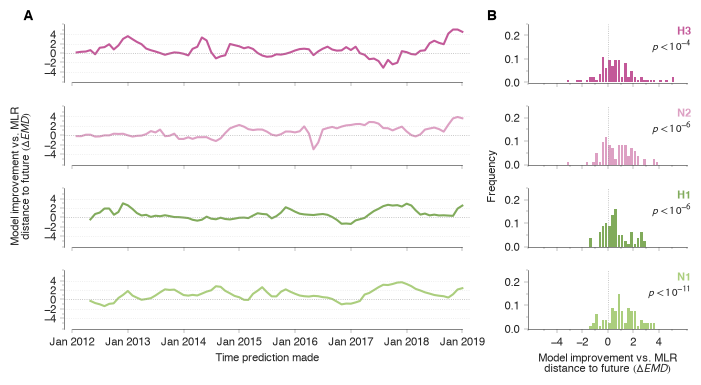

,protein,subtype,segment,paired_n,first_observation,last_observation,mean_delta_emd,median_delta_emd,t_statistic,p_value,significant_at_0.05,full_model_worse
0,H3,h3n2,ha,84,2012-02-01,2019-01-01,0.714035,0.564583,4.288703,4.825567e-05,True,False
1,N2,h3n2,na,84,2012-02-01,2019-01-01,0.764915,0.757115,5.776321,1.289496e-07,True,False
2,H1,h1n1,ha,81,2012-05-01,2019-01-01,0.639046,0.486105,5.557039,3.492922e-07,True,False
3,N1,h1n1,na,81,2012-05-01,2019-01-01,1.087462,0.946717,8.228926,2.877033e-12,True,False


/Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/supplement/fig-emd-vs-mlr-9m.pdf

In [13]:
# Supplementary Figure S11: Full model versus MLR forecasts, 9 months
INPUT_DIRECTORY = ROOT / "data" / "plotting" / "inputs" / "emd"
INPUTS = [INPUT_DIRECTORY / name for name in ("evaluations.csv", "values.csv", "methods.csv", "sources.csv")]
COMPARATOR = "MLR"
HORIZON_MONTHS = 9
# FIXED_RECIPE_METADATA: enforced inside f.plot_emd_comparison; shown here
# so the reviewed scientific choices remain visible, not as editable arguments.
EVALUATION_PROTOCOL = "results_grid"
FULL_MODEL_SOURCE = f.FULL_MODEL_SOURCE_BY_HORIZON[HORIZON_MONTHS]
WARMUP_DAYS = 1095
VERSION = "paper"
OUTPUT_FILE = ROOT / "figures" / "supplement" / "fig-emd-vs-mlr-9m.pdf"

assert all(path.is_file() for path in INPUTS)
if SAVE:
    result = f.plot_emd_comparison(
        comparator=COMPARATOR,
        horizon_months=HORIZON_MONTHS,
        input_directory=INPUT_DIRECTORY,
        version=VERSION,
        output_file=OUTPUT_FILE,
        overwrite=OVERWRITE,
    )
    display(result.figure)
    STATISTICS = display_emd_statistics(result)
    link_to(OUTPUT_FILE)


## Supplementary Figure S12 - Full model versus MLR forecasts, 12 months

**Status: RUNNABLE**

- Canonical output: `figures/supplement/fig-emd-vs-mlr-12m.pdf`
- Entry point: `figures.plot_emd_comparison`
- Data/adapter note: One explicit twelve-month MLR-comparison recipe.
- Statistical readout: `result.audit`, displayed as a paired EMD t-test table.


Input:      /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/data/plotting/inputs/emd
Comparison: full model vs multinomial logistic regression (MLR)
Horizon:    12 months (results_grid)
Full model: cross-validation-selected best GenModel [full_model_cross_validated_rare_filtered]
Appearance: paper_v1; double_over_1_9; 7.244 x 3.813 inches
Plot code:  /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/src/influenza_figures/emd_plot.py
Output:     /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/supplement/fig-emd-vs-mlr-12m.pdf
H3N2: on or after 2012-01-02 (initial inference 2009-01-02 + 1095 days; evaluation model_start_date)
H1N1: on or after 2012-05-01 (initial inference 2009-05-02 + 1095 days; evaluation model_start_date)


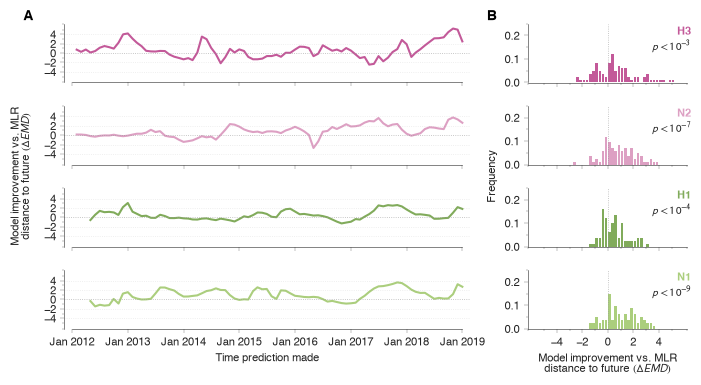

,protein,subtype,segment,paired_n,first_observation,last_observation,mean_delta_emd,median_delta_emd,t_statistic,p_value,significant_at_0.05,full_model_worse
0,H3,h3n2,ha,84,2012-02-01,2019-01-01,0.666355,0.450955,3.663878,4.364948e-04,True,False
1,N2,h3n2,na,84,2012-02-01,2019-01-01,0.835756,0.755707,6.061975,3.805524e-08,True,False
2,H1,h1n1,ha,81,2012-05-01,2019-01-01,0.498548,0.373856,4.530292,2.033591e-05,True,False
3,N1,h1n1,na,81,2012-05-01,2019-01-01,0.984696,0.771811,7.074629,5.098329e-10,True,False


/Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/supplement/fig-emd-vs-mlr-12m.pdf

In [14]:
# Supplementary Figure S12: Full model versus MLR forecasts, 12 months
INPUT_DIRECTORY = ROOT / "data" / "plotting" / "inputs" / "emd"
INPUTS = [INPUT_DIRECTORY / name for name in ("evaluations.csv", "values.csv", "methods.csv", "sources.csv")]
COMPARATOR = "MLR"
HORIZON_MONTHS = 12
# FIXED_RECIPE_METADATA: enforced inside f.plot_emd_comparison; shown here
# so the reviewed scientific choices remain visible, not as editable arguments.
EVALUATION_PROTOCOL = "results_grid"
FULL_MODEL_SOURCE = f.FULL_MODEL_SOURCE_BY_HORIZON[HORIZON_MONTHS]
WARMUP_DAYS = 1095
VERSION = "paper"
OUTPUT_FILE = ROOT / "figures" / "supplement" / "fig-emd-vs-mlr-12m.pdf"

assert all(path.is_file() for path in INPUTS)
if SAVE:
    result = f.plot_emd_comparison(
        comparator=COMPARATOR,
        horizon_months=HORIZON_MONTHS,
        input_directory=INPUT_DIRECTORY,
        version=VERSION,
        output_file=OUTPUT_FILE,
        overwrite=OVERWRITE,
    )
    display(result.figure)
    STATISTICS = display_emd_statistics(result)
    link_to(OUTPUT_FILE)


## Supplementary Figure S13 - Mutation fitness for fixed and lost mutations

**Status: RUNNABLE**

- Canonical output: `figures/supplement/fig-ds.pdf`
- Entry point: `figures.plot_background_selection`
- Data/adapter note: Canonical input: `data/plotting/inputs/background/population_fitness.csv`. The renderer selects one earliest source record per mutation identity; this figure intentionally applies no duration cutoff.
- Statistical readout: `result.audit`, with fixed/lost n, means, Welch t statistic, and p-value for each protein.


Input:         /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/data/plotting/inputs/background/population_fitness.csv
Metric:        selection coefficient
Mutations:     earliest record per identity; no duration filter
Appearance:    paper_v1; one_five_square; 4.764 x 4.764 inches
Plot code:     /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/src/influenza_figures/background_plot.py
Output:        /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/supplement/fig-ds.pdf


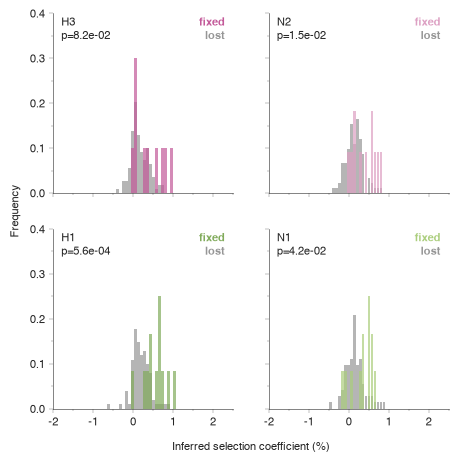

,value
figure_key,paper.ds
intended_output_name,supplement/fig-ds.pdf
profile,paper_v1
canvas_name,one_five_square
canvas_size_inches,"(4.763779527559055, 4.763779527559055)"
layout,two_by_two_fixed_lost_histograms
background_source,/Users/jpb156/Library/CloudStorage/Dropbox/git...
data_release,background_fitness_v2
event_count_before_filter,418
retained_event_count,418


Panels


,metric,metric_label,units,label,subtype,segment,minimum_duration_days,fixed_count,lost_count,fixed_mean,lost_mean,welch_t_statistic,welch_p_value
0,selection_coefficient,Inferred selection coefficient (%),percentage points,H3,h3n2,ha,None,10,109,0.396366,0.165798,1.946057,0.081546
1,selection_coefficient,Inferred selection coefficient (%),percentage points,N2,h3n2,na,None,11,91,0.408064,0.152066,2.855802,0.015001
2,selection_coefficient,Inferred selection coefficient (%),percentage points,H1,h1n1,ha,None,12,101,0.568535,0.190395,4.566055,0.000557
3,selection_coefficient,Inferred selection coefficient (%),percentage points,N1,h1n1,na,None,12,72,0.356900,0.166179,2.244802,0.041541


/Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/supplement/fig-ds.pdf

In [3]:
# Supplementary Figure S13: Mutation fitness for fixed and lost mutations
BACKGROUND_FILE = ROOT / "data" / "plotting" / "inputs" / "background" / "population_fitness.csv"
# FIXED_RECIPE_METADATA: outcomes and initial/final times were assigned
# upstream. The renderer selects the earliest start_time record per mutation.
EMERGENCE_THRESHOLD = 0.05
FIXATION_THRESHOLD = 0.95
MUTATION_IDENTITY_FIELDS = ("subtype", "segment", "position", "state")
REPRESENTATIVE_RECORD = "earliest start_time"
MINIMUM_DURATION_DAYS = None  # Figure S13 retains every selected mutation.
VERSION = "paper"
OUTPUT_FILE = ROOT / "figures" / "supplement" / "fig-ds.pdf"

assert BACKGROUND_FILE.is_file()
if SAVE:
    result = f.plot_background_selection(
        background_file=BACKGROUND_FILE,
        version=VERSION,
        output_file=OUTPUT_FILE,
        overwrite=OVERWRITE,
    )
    display(result.figure)
    AUDIT = display_figure_audit(result)
    link_to(OUTPUT_FILE)


## Supplementary Figure S14 - Initial sequence-background fitness

**Status: RUNNABLE**

- Canonical output: `figures/supplement/fig-dw-bg.pdf`
- Entry point: `figures.plot_background_initial_advantage`
- Data/adapter note: Canonical input: `data/plotting/inputs/background/population_fitness.csv`. The renderer first applies the inclusive 90-day duration cutoff and then selects the earliest eligible source record per mutation identity; source times and fixed/lost classifications remain authoritative.
- Statistical readout: `result.audit`, with fixed/lost n, means, Welch t statistic, and p-value for each protein.


Input:         /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/data/plotting/inputs/background/population_fitness.csv
Metric:        initial background fitness minus population average
Mutations:     duration >= 90 days; earliest eligible record per identity
Appearance:    paper_v1; one_five_square; 4.764 x 4.764 inches
Plot code:     /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/src/influenza_figures/background_plot.py
Output:        /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/supplement/fig-dw-bg.pdf


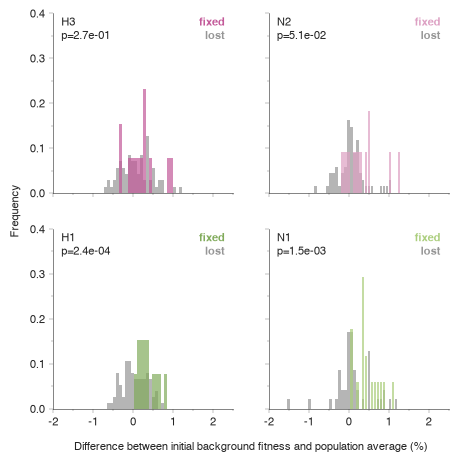

,value
figure_key,paper.dw_bg
intended_output_name,supplement/fig-dw-bg.pdf
profile,paper_v1
canvas_name,one_five_square
canvas_size_inches,"(4.763779527559055, 4.763779527559055)"
layout,two_by_two_fixed_lost_histograms
background_source,/Users/jpb156/Library/CloudStorage/Dropbox/git...
data_release,background_fitness_v2
event_count_before_filter,418
retained_event_count,315


Panels


,metric,metric_label,units,label,subtype,segment,minimum_duration_days,fixed_count,lost_count,fixed_mean,lost_mean,welch_t_statistic,welch_p_value
0,initial_background_minus_population_fitness,Difference between initial background fitness ...,percentage points,H3,h3n2,ha,90,13,71,0.215552,0.084243,1.141131,0.269655
1,initial_background_minus_population_fitness,Difference between initial background fitness ...,percentage points,N2,h3n2,na,90,11,68,0.371158,0.066755,2.165543,0.050774
2,initial_background_minus_population_fitness,Difference between initial background fitness ...,percentage points,H1,h1n1,ha,90,13,75,0.357545,0.044571,4.407611,0.000242
3,initial_background_minus_population_fitness,Difference between initial background fitness ...,percentage points,N1,h1n1,na,90,17,47,0.464535,0.117718,3.395767,0.001466


/Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/supplement/fig-dw-bg.pdf

In [3]:
# Supplementary Figure S14: Initial sequence-background fitness
BACKGROUND_FILE = ROOT / "data" / "plotting" / "inputs" / "background" / "population_fitness.csv"
# FIXED_RECIPE_METADATA: outcomes and initial/final times were assigned
# upstream. The renderer applies the inclusive duration cutoff below first, then
# selects the earliest eligible start_time record per mutation.
EMERGENCE_THRESHOLD = 0.05
FIXATION_THRESHOLD = 0.95
MUTATION_IDENTITY_FIELDS = ("subtype", "segment", "position", "state")
REPRESENTATIVE_RECORD = "earliest eligible start_time"
MINIMUM_DURATION_DAYS = 90
VERSION = "paper"
OUTPUT_FILE = ROOT / "figures" / "supplement" / "fig-dw-bg.pdf"

assert BACKGROUND_FILE.is_file()
if SAVE:
    result = f.plot_background_initial_advantage(
        background_file=BACKGROUND_FILE,
        version=VERSION,
        output_file=OUTPUT_FILE,
        overwrite=OVERWRITE,
    )
    display(result.figure)
    AUDIT = display_figure_audit(result)
    link_to(OUTPUT_FILE)


## Supplementary Figure S15 - Subsequent background-fitness growth

**Status: RUNNABLE**

- Canonical output: `figures/supplement/fig-dw-rate.pdf`
- Entry point: `figures.plot_background_growth`
- Data/adapter note: Canonical input: `data/plotting/inputs/background/population_fitness.csv`. The renderer first applies the inclusive 90-day duration cutoff and then selects the earliest eligible source record per mutation identity.
- Statistical readout: `result.audit`, with fixed/lost n, mean growth, Welch t statistic, and p-value for each protein.


Input:         /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/data/plotting/inputs/background/population_fitness.csv
Metric:        annualized background-fitness change
Mutations:     duration >= 90 days; earliest eligible record per identity
Appearance:    paper_v1; one_five_square; 4.764 x 4.764 inches
Plot code:     /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/src/influenza_figures/background_plot.py
Output:        /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/supplement/fig-dw-rate.pdf


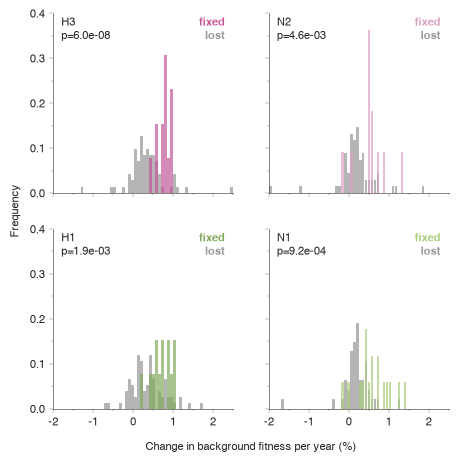

,value
figure_key,paper.dw_rate
intended_output_name,supplement/fig-dw-rate.pdf
profile,paper_v1
canvas_name,one_five_square
canvas_size_inches,"(4.763779527559055, 4.763779527559055)"
layout,two_by_two_fixed_lost_histograms
background_source,/Users/jpb156/Library/CloudStorage/Dropbox/git...
data_release,background_fitness_v2
event_count_before_filter,418
retained_event_count,315


Panels


,metric,metric_label,units,label,subtype,segment,minimum_duration_days,fixed_count,lost_count,fixed_mean,lost_mean,welch_t_statistic,welch_p_value
0,annualized_background_fitness_change,Change in background fitness per year (%),% per year,H3,h3n2,ha,90,13,71,0.787274,0.351934,6.237451,6.038164e-08
1,annualized_background_fitness_change,Change in background fitness per year (%),% per year,N2,h3n2,na,90,11,68,0.544870,0.104464,3.147258,4.587564e-03
2,annualized_background_fitness_change,Change in background fitness per year (%),% per year,H1,h1n1,ha,90,13,75,0.702527,0.399764,3.375141,1.890867e-03
3,annualized_background_fitness_change,Change in background fitness per year (%),% per year,N1,h1n1,na,90,17,47,0.623608,0.198605,3.726488,9.157383e-04


/Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/supplement/fig-dw-rate.pdf

In [4]:
# Supplementary Figure S15: Subsequent background-fitness growth
BACKGROUND_FILE = ROOT / "data" / "plotting" / "inputs" / "background" / "population_fitness.csv"
# FIXED_RECIPE_METADATA: outcomes and initial/final times were assigned
# upstream. The renderer applies the inclusive duration cutoff below first, then
# selects the earliest eligible start_time record per mutation.
EMERGENCE_THRESHOLD = 0.05
FIXATION_THRESHOLD = 0.95
MUTATION_IDENTITY_FIELDS = ("subtype", "segment", "position", "state")
REPRESENTATIVE_RECORD = "earliest eligible start_time"
MINIMUM_DURATION_DAYS = 90
GROWTH_RATE_UNITS = "percent per year"
VERSION = "paper"
OUTPUT_FILE = ROOT / "figures" / "supplement" / "fig-dw-rate.pdf"

assert BACKGROUND_FILE.is_file()
if SAVE:
    result = f.plot_background_growth(
        background_file=BACKGROUND_FILE,
        version=VERSION,
        output_file=OUTPUT_FILE,
        overwrite=OVERWRITE,
    )
    display(result.figure)
    AUDIT = display_figure_audit(result)
    link_to(OUTPUT_FILE)


## Supplementary Figure S16 - Single-site fixation AUROC

**Status: RUNNABLE**

- Canonical output: `figures/supplement/fig-auc-ss.pdf`
- Entry point: `figures.plot_single_site_auc`
- Data/adapter note: Canonical input: `data/plotting/derived/fixation_metrics/auc.csv`, filtered to rare-filtered SLM, the paper date-filtered source, and a 1,095-day minimum observation time.
- Statistical readout: `result.audit`, with exact SLM and neutral AUROC summaries.


Input:         /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/data/plotting/derived/fixation_metrics/auc.csv
Model:         slm
Source:        paper_date_filtered
Warmup:        >= 1095 days
Appearance:    paper_v1; single_tall_1_5; 3.465 x 5.197 inches
Plot code:     /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/src/influenza_figures/fixation_plot.py
Output:        /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/supplement/fig-auc-ss.pdf


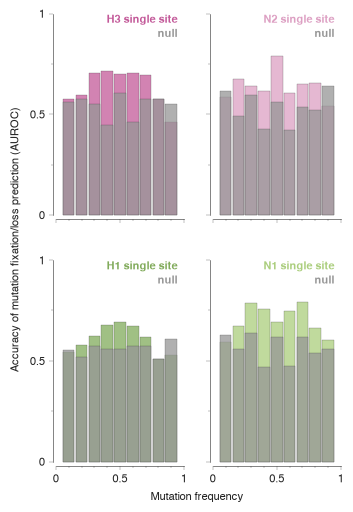

,value
figure_key,paper.auc_ss
intended_output_name,supplement/fig-auc-ss.pdf
profile,paper_v1
canvas_name,single_tall_1_5
canvas_size_inches,"(3.4645669291338583, 5.196850393700787)"
layout,two_by_two
model_id,slm
source_variant,paper_date_filtered
minimum_observation_day,1095
input_paths,(/Users/jpb156/Library/CloudStorage/Dropbox/gi...


Panels


,label,subtype,segment,fixation_probability_row_count,auc_row_count,frequency_bins,mean_model_auc,mean_null_auc,mean_delta_auc,minimum_delta_auc,maximum_delta_auc
0,H3,h3n2,ha,0,9,"(0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)",0.636014,0.545213,0.090801,-0.090577,0.267542
1,N2,h3n2,na,0,9,"(0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)",0.640577,0.533258,0.107318,-0.098829,0.227842
2,H1,h1n1,ha,0,9,"(0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)",0.604371,0.559288,0.045082,-0.080538,0.135769
3,N1,h1n1,na,0,9,"(0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)",0.701474,0.566789,0.134685,-0.032238,0.291090


/Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/supplement/fig-auc-ss.pdf

In [18]:
# Supplementary Figure S16: Single-site fixation AUROC
AUC_FILE = ROOT / "data" / "plotting" / "derived" / "fixation_metrics" / "auc.csv"
# FIXED_RECIPE_METADATA: model and source are enforced by f.plot_single_site_auc.
MODEL_ID = "slm"
SOURCE_VARIANT = "paper_date_filtered"
MINIMUM_OBSERVATION_DAY = 1095
VERSION = "paper"
OUTPUT_FILE = ROOT / "figures" / "supplement" / "fig-auc-ss.pdf"

assert AUC_FILE.is_file()
if SAVE:
    result = f.plot_single_site_auc(
        auc_file=AUC_FILE,
        minimum_observation_day=MINIMUM_OBSERVATION_DAY,
        version=VERSION,
        output_file=OUTPUT_FILE,
        overwrite=OVERWRITE,
    )
    display(result.figure)
    AUDIT = display_figure_audit(result)
    link_to(OUTPUT_FILE)


## Supplementary Figure S17 - Full model versus single-site forecasts, 6 months

**Status: RUNNABLE**

- Canonical output: `figures/supplement/fig-emd-vs-slm-6m.pdf`
- Entry point: `figures.plot_emd_comparison`
- Data/adapter note: SLM is the rare-filtered single-site (single-locus) model. This is one explicit six-month comparison recipe.
- Statistical readout: `result.audit`, displayed as a paired EMD t-test table.


Input:      /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/data/plotting/inputs/emd
Comparison: full model vs single-locus model (SLM)
Horizon:    6 months (results_grid)
Full model: cross-validation-selected best GenModel [full_model_cross_validated_rare_filtered]
Appearance: paper_v1; double_over_1_9; 7.244 x 3.813 inches
Plot code:  /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/src/influenza_figures/emd_plot.py
Output:     /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/supplement/fig-emd-vs-slm-6m.pdf
H3N2: on or after 2012-01-02 (initial inference 2009-01-02 + 1095 days; evaluation model_start_date)
H1N1: on or after 2012-05-01 (initial inference 2009-05-02 + 1095 days; evaluation model_start_date)


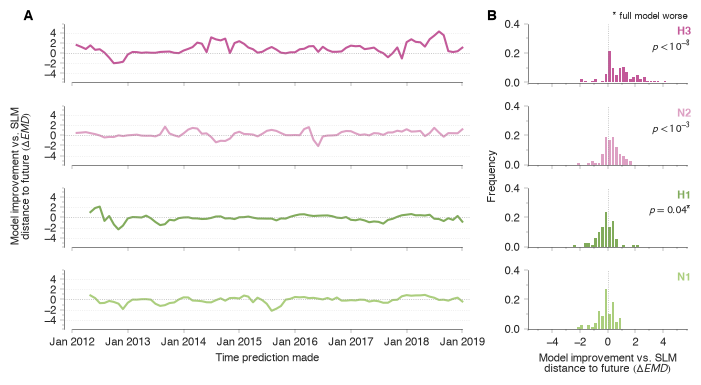

,protein,subtype,segment,paired_n,first_observation,last_observation,mean_delta_emd,median_delta_emd,t_statistic,p_value,significant_at_0.05,full_model_worse
0,H3,h3n2,ha,84,2012-02-01,2019-01-01,0.848254,0.749006,6.747237,1.889362e-09,True,False
1,N2,h3n2,na,84,2012-02-01,2019-01-01,0.243518,0.255152,3.474005,8.174806e-04,True,False
2,H1,h1n1,ha,81,2012-05-01,2019-01-01,-0.152180,-0.178180,-2.069550,4.172220e-02,True,True
3,N1,h1n1,na,81,2012-05-01,2019-01-01,-0.127755,-0.063044,-1.870123,6.512453e-02,False,False


/Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/supplement/fig-emd-vs-slm-6m.pdf

In [19]:
# Supplementary Figure S17: Full model versus single-site forecasts, 6 months
INPUT_DIRECTORY = ROOT / "data" / "plotting" / "inputs" / "emd"
INPUTS = [INPUT_DIRECTORY / name for name in ("evaluations.csv", "values.csv", "methods.csv", "sources.csv")]
COMPARATOR = "SLM"
HORIZON_MONTHS = 6
# FIXED_RECIPE_METADATA: enforced inside f.plot_emd_comparison; shown here
# so the reviewed scientific choices remain visible, not as editable arguments.
EVALUATION_PROTOCOL = "results_grid"
FULL_MODEL_SOURCE = f.FULL_MODEL_SOURCE_BY_HORIZON[HORIZON_MONTHS]
WARMUP_DAYS = 1095
VERSION = "paper"
OUTPUT_FILE = ROOT / "figures" / "supplement" / "fig-emd-vs-slm-6m.pdf"

assert all(path.is_file() for path in INPUTS)
if SAVE:
    result = f.plot_emd_comparison(
        comparator=COMPARATOR,
        horizon_months=HORIZON_MONTHS,
        input_directory=INPUT_DIRECTORY,
        version=VERSION,
        output_file=OUTPUT_FILE,
        overwrite=OVERWRITE,
    )
    display(result.figure)
    STATISTICS = display_emd_statistics(result)
    link_to(OUTPUT_FILE)


## Supplementary Figure S18 - Full model versus single-site forecasts, 9 months

**Status: RUNNABLE**

- Canonical output: `figures/supplement/fig-emd-vs-slm-9m.pdf`
- Entry point: `figures.plot_emd_comparison`
- Data/adapter note: SLM is the rare-filtered single-site (single-locus) model. This is one explicit nine-month comparison recipe.
- Statistical readout: `result.audit`, displayed as a paired EMD t-test table.


Input:      /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/data/plotting/inputs/emd
Comparison: full model vs single-locus model (SLM)
Horizon:    9 months (results_grid)
Full model: cross-validation-selected best GenModel [full_model_cross_validated_rare_filtered]
Appearance: paper_v1; double_over_1_9; 7.244 x 3.813 inches
Plot code:  /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/src/influenza_figures/emd_plot.py
Output:     /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/supplement/fig-emd-vs-slm-9m.pdf
H3N2: on or after 2012-01-02 (initial inference 2009-01-02 + 1095 days; evaluation model_start_date)
H1N1: on or after 2012-05-01 (initial inference 2009-05-02 + 1095 days; evaluation model_start_date)


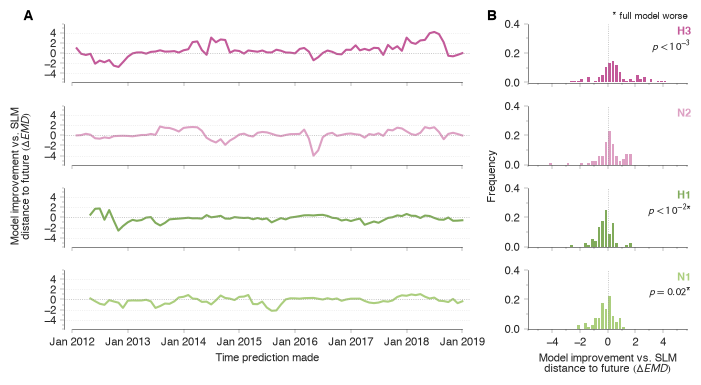

,protein,subtype,segment,paired_n,first_observation,last_observation,mean_delta_emd,median_delta_emd,t_statistic,p_value,significant_at_0.05,full_model_worse
0,H3,h3n2,ha,84,2012-02-01,2019-01-01,0.518525,0.380098,3.585518,0.000567,True,False
1,N2,h3n2,na,84,2012-02-01,2019-01-01,0.145532,0.151959,1.435778,0.154824,False,False
2,H1,h1n1,ha,81,2012-05-01,2019-01-01,-0.219559,-0.183004,-2.980725,0.003808,True,True
3,N1,h1n1,na,81,2012-05-01,2019-01-01,-0.181414,-0.134234,-2.412055,0.018152,True,True


/Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/supplement/fig-emd-vs-slm-9m.pdf

In [20]:
# Supplementary Figure S18: Full model versus single-site forecasts, 9 months
INPUT_DIRECTORY = ROOT / "data" / "plotting" / "inputs" / "emd"
INPUTS = [INPUT_DIRECTORY / name for name in ("evaluations.csv", "values.csv", "methods.csv", "sources.csv")]
COMPARATOR = "SLM"
HORIZON_MONTHS = 9
# FIXED_RECIPE_METADATA: enforced inside f.plot_emd_comparison; shown here
# so the reviewed scientific choices remain visible, not as editable arguments.
EVALUATION_PROTOCOL = "results_grid"
FULL_MODEL_SOURCE = f.FULL_MODEL_SOURCE_BY_HORIZON[HORIZON_MONTHS]
WARMUP_DAYS = 1095
VERSION = "paper"
OUTPUT_FILE = ROOT / "figures" / "supplement" / "fig-emd-vs-slm-9m.pdf"

assert all(path.is_file() for path in INPUTS)
if SAVE:
    result = f.plot_emd_comparison(
        comparator=COMPARATOR,
        horizon_months=HORIZON_MONTHS,
        input_directory=INPUT_DIRECTORY,
        version=VERSION,
        output_file=OUTPUT_FILE,
        overwrite=OVERWRITE,
    )
    display(result.figure)
    STATISTICS = display_emd_statistics(result)
    link_to(OUTPUT_FILE)


## Supplementary Figure S19 - Full model versus single-site forecasts, 12 months

**Status: RUNNABLE**

- Canonical output: `figures/supplement/fig-emd-vs-slm-12m.pdf`
- Entry point: `figures.plot_emd_comparison`
- Data/adapter note: SLM is the rare-filtered single-site (single-locus) model. This is one explicit twelve-month comparison recipe.
- Statistical readout: `result.audit`, displayed as a paired EMD t-test table.


Input:      /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/data/plotting/inputs/emd
Comparison: full model vs single-locus model (SLM)
Horizon:    12 months (results_grid)
Full model: cross-validation-selected best GenModel [full_model_cross_validated_rare_filtered]
Appearance: paper_v1; double_over_1_9; 7.244 x 3.813 inches
Plot code:  /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/src/influenza_figures/emd_plot.py
Output:     /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/supplement/fig-emd-vs-slm-12m.pdf
H3N2: on or after 2012-01-02 (initial inference 2009-01-02 + 1095 days; evaluation model_start_date)
H1N1: on or after 2012-05-01 (initial inference 2009-05-02 + 1095 days; evaluation model_start_date)


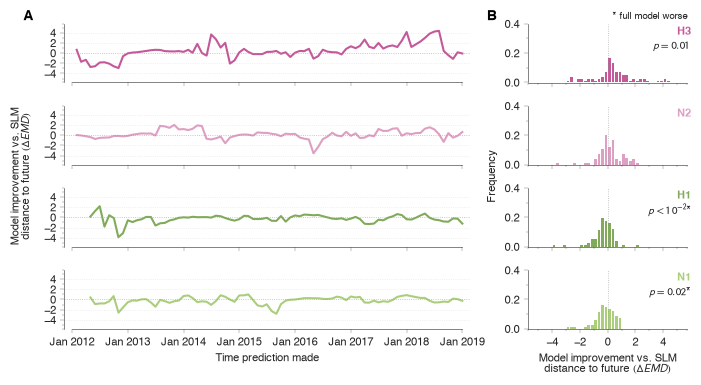

,protein,subtype,segment,paired_n,first_observation,last_observation,mean_delta_emd,median_delta_emd,t_statistic,p_value,significant_at_0.05,full_model_worse
0,H3,h3n2,ha,84,2012-02-01,2019-01-01,0.436804,0.325290,2.633368,0.010082,True,False
1,N2,h3n2,na,84,2012-02-01,2019-01-01,0.145445,0.101885,1.488990,0.140280,False,False
2,H1,h1n1,ha,81,2012-05-01,2019-01-01,-0.285340,-0.191203,-3.212937,0.001894,True,True
3,N1,h1n1,na,81,2012-05-01,2019-01-01,-0.198027,-0.132394,-2.417735,0.017891,True,True


/Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/supplement/fig-emd-vs-slm-12m.pdf

In [21]:
# Supplementary Figure S19: Full model versus single-site forecasts, 12 months
INPUT_DIRECTORY = ROOT / "data" / "plotting" / "inputs" / "emd"
INPUTS = [INPUT_DIRECTORY / name for name in ("evaluations.csv", "values.csv", "methods.csv", "sources.csv")]
COMPARATOR = "SLM"
HORIZON_MONTHS = 12
# FIXED_RECIPE_METADATA: enforced inside f.plot_emd_comparison; shown here
# so the reviewed scientific choices remain visible, not as editable arguments.
EVALUATION_PROTOCOL = "results_grid"
FULL_MODEL_SOURCE = f.FULL_MODEL_SOURCE_BY_HORIZON[HORIZON_MONTHS]
WARMUP_DAYS = 1095
VERSION = "paper"
OUTPUT_FILE = ROOT / "figures" / "supplement" / "fig-emd-vs-slm-12m.pdf"

assert all(path.is_file() for path in INPUTS)
if SAVE:
    result = f.plot_emd_comparison(
        comparator=COMPARATOR,
        horizon_months=HORIZON_MONTHS,
        input_directory=INPUT_DIRECTORY,
        version=VERSION,
        output_file=OUTPUT_FILE,
        overwrite=OVERWRITE,
    )
    display(result.figure)
    STATISTICS = display_emd_statistics(result)
    link_to(OUTPUT_FILE)


# Diagnostics and alternatives

These cells are deliberately outside the manuscript sequence. They are useful
for checking model choices or regenerating reusable components, but they are
not separate figures in the attached draft.


## Diagnostic - Cross-validated best model versus baseline

**Status: RUNNABLE**

The cells below pair `best GenModel` with `GenModel (baseline)` by exact
`evaluation_id` after the same 1,095-day warmup. Delta EMD is baseline minus
best, so positive values favor the cross-validation-selected model. Outputs
belong under `figures/diagnostic/`; each cell displays its audit table.


Input:      /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/data/plotting/inputs/emd
Comparison: cross-validation-selected best GenModel vs baseline GenModel
Delta:      baseline EMD - best EMD (positive favors best GenModel)
Horizon:    6 months (results_grid)
Full model: cross-validation-selected best GenModel [full_model_cross_validated_rare_filtered]
Baseline:   GenModel (baseline) [full_model_rare_filtered]
Appearance: paper_v1; double_over_1_9; 7.244 x 3.813 inches
Plot code:  /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/src/influenza_figures/emd_plot.py
Output:     /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/diagnostic/fig-emd-best-vs-baseline-6m.pdf
H3N2: on or after 2012-01-02 (initial inference 2009-01-02 + 1095 days; evaluation model_start_date)
H1N1: on or after 2012-05-01 (initial inference 2009-05-02 + 1095 days; evaluation model_start_date)


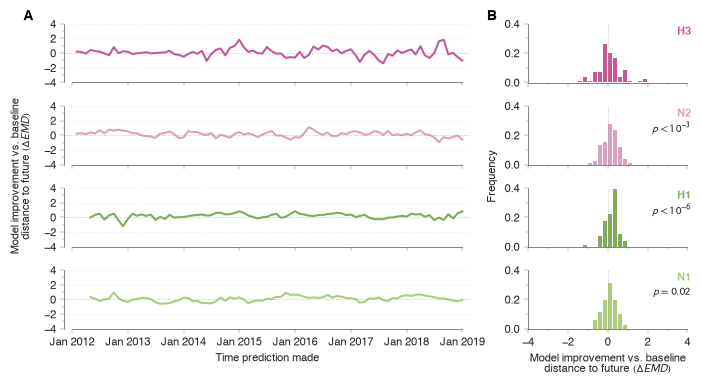

,protein,subtype,segment,paired_n,first_observation,last_observation,mean_delta_emd,median_delta_emd,t_statistic,p_value,significant_at_0.05,full_model_worse
0,H3,h3n2,ha,84,2012-02-01,2019-01-01,0.086924,0.031320,1.367439,1.751794e-01,False,False
1,N2,h3n2,na,84,2012-02-01,2019-01-01,0.139866,0.147078,3.525858,6.901675e-04,True,False
2,H1,h1n1,ha,81,2012-05-01,2019-01-01,0.199594,0.258621,5.377222,7.304365e-07,True,False
3,N1,h1n1,na,81,2012-05-01,2019-01-01,0.091505,0.126526,2.349807,2.124842e-02,True,False


/Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/diagnostic/fig-emd-best-vs-baseline-6m.pdf

In [22]:
# Diagnostic: best GenModel versus baseline, 6 months
INPUT_DIRECTORY = ROOT / "data" / "plotting" / "inputs" / "emd"
INPUTS = [INPUT_DIRECTORY / name for name in ("evaluations.csv", "values.csv", "methods.csv", "sources.csv")]
HORIZON_MONTHS = 6
# FIXED_RECIPE_METADATA: enforced inside f.plot_emd_best_vs_baseline; shown
# here so the reviewed protocol and warmup remain visible.
EVALUATION_PROTOCOL = "results_grid"
WARMUP_DAYS = 1095
DELTA_EMD = "baseline EMD - best-model EMD"  # positive favors best GenModel
VERSION = "paper"
OUTPUT_FILE = ROOT / "figures" / "diagnostic" / "fig-emd-best-vs-baseline-6m.pdf"

assert all(path.is_file() for path in INPUTS)
if SAVE:
    result = f.plot_emd_best_vs_baseline(
        horizon_months=HORIZON_MONTHS,
        input_directory=INPUT_DIRECTORY,
        version=VERSION,
        output_file=OUTPUT_FILE,
        overwrite=OVERWRITE,
    )
    display(result.figure)
    STATISTICS = display_emd_statistics(result)
    link_to(OUTPUT_FILE)


Input:      /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/data/plotting/inputs/emd
Comparison: cross-validation-selected best GenModel vs baseline GenModel
Delta:      baseline EMD - best EMD (positive favors best GenModel)
Horizon:    9 months (results_grid)
Full model: cross-validation-selected best GenModel [full_model_cross_validated_rare_filtered]
Baseline:   GenModel (baseline) [full_model_rare_filtered]
Appearance: paper_v1; double_over_1_9; 7.244 x 3.813 inches
Plot code:  /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/src/influenza_figures/emd_plot.py
Output:     /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/diagnostic/fig-emd-best-vs-baseline-9m.pdf
H3N2: on or after 2012-01-02 (initial inference 2009-01-02 + 1095 days; evaluation model_start_date)
H1N1: on or after 2012-05-01 (initial inference 2009-05-02 + 1095 days; evaluation model_start_date)


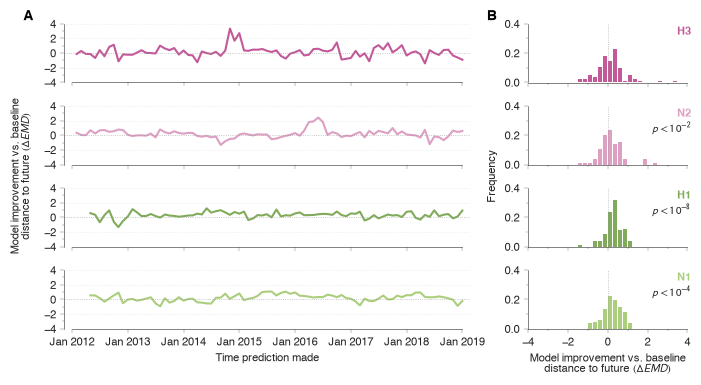

,protein,subtype,segment,paired_n,first_observation,last_observation,mean_delta_emd,median_delta_emd,t_statistic,p_value,significant_at_0.05,full_model_worse
0,H3,h3n2,ha,84,2012-02-01,2019-01-01,0.158775,0.128962,1.951694,5.434714e-02,False,False
1,N2,h3n2,na,84,2012-02-01,2019-01-01,0.188542,0.111023,2.958440,4.027406e-03,True,False
2,H1,h1n1,ha,81,2012-05-01,2019-01-01,0.306603,0.301558,6.471242,7.213470e-09,True,False
3,N1,h1n1,na,81,2012-05-01,2019-01-01,0.218286,0.234864,4.233193,6.101665e-05,True,False


/Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/diagnostic/fig-emd-best-vs-baseline-9m.pdf

In [23]:
# Diagnostic: best GenModel versus baseline, 9 months
INPUT_DIRECTORY = ROOT / "data" / "plotting" / "inputs" / "emd"
INPUTS = [INPUT_DIRECTORY / name for name in ("evaluations.csv", "values.csv", "methods.csv", "sources.csv")]
HORIZON_MONTHS = 9
# FIXED_RECIPE_METADATA: enforced inside f.plot_emd_best_vs_baseline; shown
# here so the reviewed protocol and warmup remain visible.
EVALUATION_PROTOCOL = "results_grid"
WARMUP_DAYS = 1095
DELTA_EMD = "baseline EMD - best-model EMD"  # positive favors best GenModel
VERSION = "paper"
OUTPUT_FILE = ROOT / "figures" / "diagnostic" / "fig-emd-best-vs-baseline-9m.pdf"

assert all(path.is_file() for path in INPUTS)
if SAVE:
    result = f.plot_emd_best_vs_baseline(
        horizon_months=HORIZON_MONTHS,
        input_directory=INPUT_DIRECTORY,
        version=VERSION,
        output_file=OUTPUT_FILE,
        overwrite=OVERWRITE,
    )
    display(result.figure)
    STATISTICS = display_emd_statistics(result)
    link_to(OUTPUT_FILE)


Input:      /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/data/plotting/inputs/emd
Comparison: cross-validation-selected best GenModel vs baseline GenModel
Delta:      baseline EMD - best EMD (positive favors best GenModel)
Horizon:    12 months (results_grid)
Full model: cross-validation-selected best GenModel [full_model_cross_validated_rare_filtered]
Baseline:   GenModel (baseline) [full_model_rare_filtered]
Appearance: paper_v1; double_over_1_9; 7.244 x 3.813 inches
Plot code:  /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/src/influenza_figures/emd_plot.py
Output:     /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/diagnostic/fig-emd-best-vs-baseline-12m.pdf
H3N2: on or after 2012-01-02 (initial inference 2009-01-02 + 1095 days; evaluation model_start_date)
H1N1: on or after 2012-05-01 (initial inference 2009-05-02 + 1095 days; evaluation model_start_date)


/Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/src/influenza_figures/emd_plot.py:607: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  figure = plt.figure(figsize=resolved_spec.canvas.size_inches)


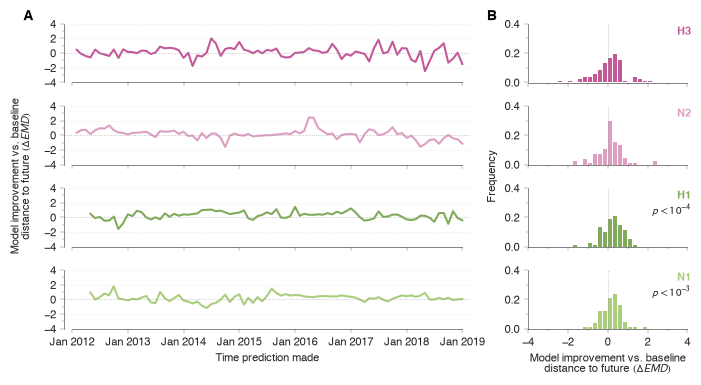

,protein,subtype,segment,paired_n,first_observation,last_observation,mean_delta_emd,median_delta_emd,t_statistic,p_value,significant_at_0.05,full_model_worse
0,H3,h3n2,ha,84,2012-02-01,2019-01-01,0.089054,0.139332,1.080710,0.282956,False,False
1,N2,h3n2,na,84,2012-02-01,2019-01-01,0.134107,0.139785,1.855925,0.067013,False,False
2,H1,h1n1,ha,81,2012-05-01,2019-01-01,0.258709,0.344862,4.462884,0.000026,True,False
3,N1,h1n1,na,81,2012-05-01,2019-01-01,0.204139,0.240727,3.792846,0.000288,True,False


/Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/diagnostic/fig-emd-best-vs-baseline-12m.pdf

In [24]:
# Diagnostic: best GenModel versus baseline, 12 months
INPUT_DIRECTORY = ROOT / "data" / "plotting" / "inputs" / "emd"
INPUTS = [INPUT_DIRECTORY / name for name in ("evaluations.csv", "values.csv", "methods.csv", "sources.csv")]
HORIZON_MONTHS = 12
# FIXED_RECIPE_METADATA: enforced inside f.plot_emd_best_vs_baseline; shown
# here so the reviewed protocol and warmup remain visible.
EVALUATION_PROTOCOL = "results_grid"
WARMUP_DAYS = 1095
DELTA_EMD = "baseline EMD - best-model EMD"  # positive favors best GenModel
VERSION = "paper"
OUTPUT_FILE = ROOT / "figures" / "diagnostic" / "fig-emd-best-vs-baseline-12m.pdf"

assert all(path.is_file() for path in INPUTS)
if SAVE:
    result = f.plot_emd_best_vs_baseline(
        horizon_months=HORIZON_MONTHS,
        input_directory=INPUT_DIRECTORY,
        version=VERSION,
        output_file=OUTPUT_FILE,
        overwrite=OVERWRITE,
    )
    display(result.figure)
    STATISTICS = display_emd_statistics(result)
    link_to(OUTPUT_FILE)


## Alternative component - Standalone H3N2 HA clade forecast

**Status: RUNNABLE**

- Output: `figures/paper/fig-clade.pdf`
- Entry point: `figures.plot_clade_figure`
- Relationship to manuscript: this is the reusable clade component of Main
  Figure 5, not the final combined figure.


In [25]:
INPUT_FILE = ROOT / "data" / "plotting" / "inputs" / "clades" / "h3n2_ha_frequencies.csv"
OUTPUT_FILE = ROOT / "figures" / "paper" / "fig-clade.pdf"
VERSION = "paper"
MINIMUM_TOTAL_FREQUENCY = 1.0
START_DATE = "2011-08-01"
END_DATE = "2015-06-01"
FORECAST_BASELINE_DATE = "2014-06-01"
FIGSIZE_INCHES = f.CLADE_PAPER_CANVAS_INCHES

assert INPUT_FILE.is_file()
if SAVE:
    clade_audit = f.plot_clade_figure(
        input_file=INPUT_FILE,
        output_file=OUTPUT_FILE,
        version=VERSION,
        minimum_total_frequency=MINIMUM_TOTAL_FREQUENCY,
        start_date=START_DATE,
        end_date=END_DATE,
        forecast_baseline_date=FORECAST_BASELINE_DATE,
        overwrite=OVERWRITE,
    )
    display(clade_audit)
    link_to(OUTPUT_FILE)


Input:      /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/data/plotting/inputs/clades/h3n2_ha_frequencies.csv
Selection:  total observed frequency > 1.0
Dates:      2011-08-01 < date < 2015-06-01
Clades:     3C, 3C.2, 3C.2a, 3C.3, 3C.3a, 3C.3b
Appearance: paper_v1; legacy single-column canvas; 3.465 x 4.157 inches
Plot code:  /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/src/influenza_figures/legacy/figures.py (plot_clade)
Output:     /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/paper/fig-clade.pdf


{'output_file': PosixPath('/Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/paper/fig-clade.pdf'),
 'selected_clades': ('3C', '3C.2', '3C.2a', '3C.3', '3C.3a', '3C.3b'),
 'row_counts': {'observed_history': 624, 'observed_full': 846, 'forecast': 24}}

/Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/paper/fig-clade.pdf

## Alternative component - Standalone fixation-probability plot

**Status: PENDING ADAPTER**

- Intended output: `figures/paper/fig-pfix.pdf`
- Planned entry point: `figures.plot_pfix_single`; historical implementation
  `figures.legacy.plot_pfix_single`.
- Relationship to manuscript: useful as a check, but the draft uses the
  combined Main Figure 3 layout.


## Alternative assembly - Combined 9-month EMD and clade plot

**Status: PENDING ADAPTER**

- Intended output: `figures/paper/fig-emd-clade.pdf`
- Planned entry point: a canonical replacement for
  `figures.legacy.plot_emd_clade`.
- Canonical EMD and clade preparation are independently available, but the old
  combined renderer expects retired wide clade tables.


## Presentation alternative - Allele-frequency slide panels

**Status: RUNNABLE**

This preserved recipe is not a manuscript figure. It keeps the explicit H1
time shift, protein colors, slide canvas, and one canonical input per panel.


In [26]:
VERSION = "slides"
FIGSIZE_INCHES = f.FREQUENCY_SLIDE_CANVAS_INCHES
FREQUENCY_SLIDES = [
    {
        "input_file": ROOT / "data" / "plotting" / "inputs" / "frequencies" / "h3n2_ha_allele_frequencies.txt",
        "subtype": "h3n2", "segment": "ha", "time_shift_days": 0, "color": "#C35999",
        "output_file": ROOT / "figures" / "slides" / "fig-H3N2-HA-frequency-slides.pdf",
    },
    {
        "input_file": ROOT / "data" / "plotting" / "inputs" / "frequencies" / "h3n2_na_allele_frequencies.txt",
        "subtype": "h3n2", "segment": "na", "time_shift_days": 0, "color": "#DDA0C3",
        "output_file": ROOT / "figures" / "slides" / "fig-H3N2-NA-frequency-slides.pdf",
    },
    {
        "input_file": ROOT / "data" / "plotting" / "inputs" / "frequencies" / "h1n1_ha_allele_frequencies.txt",
        "subtype": "h1n1", "segment": "ha", "time_shift_days": 120, "color": "#81AB5B",
        "output_file": ROOT / "figures" / "slides" / "fig-H1N1-HA-frequency-slides.pdf",
    },
    {
        "input_file": ROOT / "data" / "plotting" / "inputs" / "frequencies" / "h1n1_na_allele_frequencies.txt",
        "subtype": "h1n1", "segment": "na", "time_shift_days": 120, "color": "#ABCE7D",
        "output_file": ROOT / "figures" / "slides" / "fig-H1N1-NA-frequency-slides.pdf",
    },
]

assert all(recipe["input_file"].is_file() for recipe in FREQUENCY_SLIDES)
if SAVE:
    for recipe in FREQUENCY_SLIDES:
        output = f.plot_frequency_slide(
            **recipe,
            version=VERSION,
            overwrite=OVERWRITE,
        )
        link_to(output)


Input:      /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/data/plotting/inputs/frequencies/h3n2_ha_allele_frequencies.txt
Protein:    H3N2 HA
Time shift: 0 days
Appearance: slides_v1; 8.5 x 1.6 inches
Plot code:  /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/src/influenza_figures/legacy/figures.py (plot_frequency_slides)
Output:     /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/slides/fig-H3N2-HA-frequency-slides.pdf


/Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/slides/fig-H3N2-HA-frequency-slides.pdf

Input:      /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/data/plotting/inputs/frequencies/h3n2_na_allele_frequencies.txt
Protein:    H3N2 NA
Time shift: 0 days
Appearance: slides_v1; 8.5 x 1.6 inches
Plot code:  /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/src/influenza_figures/legacy/figures.py (plot_frequency_slides)
Output:     /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/slides/fig-H3N2-NA-frequency-slides.pdf


/Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/slides/fig-H3N2-NA-frequency-slides.pdf

Input:      /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/data/plotting/inputs/frequencies/h1n1_ha_allele_frequencies.txt
Protein:    H1N1 HA
Time shift: 120 days
Appearance: slides_v1; 8.5 x 1.6 inches
Plot code:  /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/src/influenza_figures/legacy/figures.py (plot_frequency_slides)
Output:     /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/slides/fig-H1N1-HA-frequency-slides.pdf


/Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/slides/fig-H1N1-HA-frequency-slides.pdf

Input:      /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/data/plotting/inputs/frequencies/h1n1_na_allele_frequencies.txt
Protein:    H1N1 NA
Time shift: 120 days
Appearance: slides_v1; 8.5 x 1.6 inches
Plot code:  /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/src/influenza_figures/legacy/figures.py (plot_frequency_slides)
Output:     /Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/slides/fig-H1N1-NA-frequency-slides.pdf


/Users/jpb156/Library/CloudStorage/Dropbox/git/paper-influenza-prediction/figures/slides/fig-H1N1-NA-frequency-slides.pdf

## Modifying a plot

Start with the manuscript-numbered cell above. Change the visible data,
scientific, and output choices in that cell. A named wrapper in `figures.py`
keeps preparation and presentation together and prints the exact source file
containing the axes and marks. Historical functions remain available through
`figures.legacy`, but a **PENDING ADAPTER** entry should not be turned into a
run cell merely by pointing it at archived paths or retired schemas.
